# TP 1 — Advanced Data Detective
## Streaming Service Subscription Churn & Content Viewing

**Institution:** EPITA — School of Engineering and Computer Science
**Module:** DEP (Exploratory Data Analysis) — Specialization Lab
**Group:** Group 5
**Dataset:** `dataset.csv` — 5,200 synthetic subscription records, 14 columns

---

### What this notebook demonstrates

1. **First contact & grain definition** — what one row means, and why identity is unreliable.
2. **Schema coercion & memory optimization** — string cleaning, type coercion, categorical compression.
3. **Missingness profiling & triage** — separating structural blanks, injected missingness, and recoverable gaps.
4. **Deduplication & outlier forensics** — merging complementary duplicate records and identifying a deliberate sentinel-corruption pattern.
5. **Five business questions** — each answered with pandas transformations, an annotated chart, and a one-sentence executive takeaway.
6. **Leakage-free ML preparation** — stratified split before any transformer, train-only imputation/encoding/scaling, and exported `train_prepared.csv` / `test_prepared.csv`.

### Headline findings

- **Basic plan churn is the clearest commercial problem:** 42.9% churn versus 27.0% for Standard and 28.0% for Premium (χ² p < 0.001).
- **Satisfaction score 1 is the strongest behavioral red flag:** 69.0% churn versus 25.9% for every other score (risk ratio ≈ 2.66), reaching 79.8% among Basic subscribers.
- **Promo usage shows no retention or pricing benefit** in this dataset: 33.3% vs 33.6% churn (p = 0.89), with nearly identical monthly prices.
- **Watch time and genre breadth are not churn differentiators**; device type is also a null result.
- **Lifecycle evidence is directionally consistent but underpowered:** churned users show a shorter observed active period, but only 183 rows have usable dates.

### Reproducibility

- Python 3.12; dependencies pinned in `pyproject.toml` / `uv.lock` (pip fallback: `requirements.txt`).
- `RANDOM_STATE = 42` for the split and bootstrap.
- Run the notebook from the repository root so `dataset.csv` resolves correctly.
- Outputs: `dataset_cleaned.csv`, `train_prepared.csv`, `test_prepared.csv`.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#0b0b0b",
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "font.family": "sans-serif",
    }
)

RANDOM_STATE = 42
DATA_PATH = Path("dataset.csv")

# Validated categorical slots from the project design system.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
GRAY = "#898781"
INK = "#0b0b0b"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

PLAN_ORDER = ["Basic", "Standard", "Premium"]


def wilson_ci(successes, n, z=1.96):
    """Wilson score interval for a proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return centre - half, centre + half


def pct(x, digits=1):
    return f"{x:.{digits}%}"


def annotate_bars(ax, bars, labels, fontsize=9, y_offset=0.012):
    """Place a short label above each bar, in axes coordinates for stability."""
    ymax = ax.get_ylim()[1]
    for bar, label in zip(bars, labels):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + ymax * y_offset,
            label,
            ha="center",
            va="bottom",
            fontsize=fontsize,
            color=INK,
        )


print("Environment ready.")
print(f"Source data: {DATA_PATH.resolve()}")

Environment ready.
Source data: /Users/macbookpro/Streaming_Service_Subscription_Churn_Content_Viewing_Group5/dataset.csv


---
# Part 1 — First Contact & Grain Definition

Before touching a single value, we need to know **what one row represents**. That
decision controls every downstream aggregation and every model split.

The dataset has two identity columns (`user_id`, `subscription_id`), a lifecycle
pair (`registration_date`, `last_active_date`), commercial attributes, engagement
metrics, and a binary outcome (`churned`). The intended grain is **one row per
subscription**. If `user_id` and `subscription_id` are not 1:1, we have injected
duplicates or corrupted identifiers to resolve.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)

print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print("\nRaw dtypes (everything is text at this stage):")
print(raw.dtypes.to_string())

display(raw.head(8))

Shape: 5,200 rows × 14 columns

Raw dtypes (everything is text at this stage):
user_id                       str
subscription_id               str
registration_date             str
plan_type                     str
country                       str
device_type                   str
monthly_price                 str
total_watch_minutes           str
num_genres_watched            str
has_kids_profile              str
promo_code_used               str
last_active_date              str
churned                       str
content_satisfaction_score    str


,user_id,subscription_id,registration_date,plan_type,country,device_type,monthly_price,total_watch_minutes,num_genres_watched,has_kids_profile,promo_code_used,last_active_date,churned,content_satisfaction_score
0,1127,SUB_0001127,2023-09-21,Basic,Germany,Desktop,,4360,6,0,,2023-09-29,1,5
1,80,SUB_0000080,,Basic,UK,Gaming Console,,8263,5,0,WELCOME10,,0,4
2,3261,SUB_0003261,2023-02-20,Basic,USA,Desktop,,2866,4,0,,2023-08-15,0,1
3,1737,SUB_0001737,,Standard,Brazil,Smart TV,,0,11,0,SPRING20,,0,1
4,4527,SUB_0004527,,Standard,Japan,Mobile,,4146,6,1,,,0,5
5,3594,SUB_0003594,2020-02-24,Standard,,Tablet,,4999,1,0,,2022-08-04,0,5
6,4047,SUB_0004047,,Basic,Canada,Mobile,,6277,5,0,,,1,1
7,2893,SUB_0002893,,Standard,Japan,,14.87,8743,4,0,,,0,2


In [3]:
profile_rows = []
for col in raw.columns:
    s = raw[col].str.strip()
    non_blank = s.ne("")
    samples = ", ".join(map(str, s[non_blank].unique()[:3]))
    profile_rows.append(
        {
            "column": col,
            "non_blank": int(non_blank.sum()),
            "blank_pct": 100 * (~non_blank).mean(),
            "distinct_non_blank": int(s[non_blank].nunique()),
            "sample_values": samples,
        }
    )
column_profile = pd.DataFrame(profile_rows)
display(column_profile)

,column,non_blank,blank_pct,distinct_non_blank,sample_values
0,user_id,4756,8.538462,4536,"1127, 80, 3261"
1,subscription_id,4537,12.750000,4363,"SUB_0001127, SUB_0000080, SUB_0003261"
2,registration_date,983,81.096154,684,"2023-09-21, 2023-02-20, 2020-02-24"
3,plan_type,4779,8.096154,12,"Basic, Standard, standard"
4,country,4778,8.115385,8,"Germany, UK, USA"
5,device_type,4779,8.096154,5,"Desktop, Gaming Console, Smart TV"
6,monthly_price,1222,76.500000,511,"14.87, 14.46, 9.68"
7,total_watch_minutes,5200,0.000000,3363,"4360, 8263, 2866"
8,num_genres_watched,5200,0.000000,26,"6, 5, 4"
9,has_kids_profile,5200,0.000000,6,"0, 1, 12"


In [4]:
exact_duplicates = int(raw.duplicated().sum())

uid = raw["user_id"].str.strip()
sid = raw["subscription_id"].str.strip()
uid_nonblank = uid[uid.ne("")]
sid_nonblank = sid[sid.ne("")]

grain_evidence = pd.DataFrame(
    [
        {"check": "Rows in file", "value": len(raw)},
        {"check": "Exact duplicate rows", "value": exact_duplicates},
        {"check": "Distinct non-blank user_id", "value": uid_nonblank.nunique()},
        {"check": "Distinct non-blank subscription_id", "value": sid_nonblank.nunique()},
        {"check": "user_id groups with >1 row", "value": int((uid_nonblank.value_counts() > 1).sum())},
        {"check": "subscription_id groups with >1 row", "value": int((sid_nonblank.value_counts() > 1).sum())},
        {"check": "Rows with both IDs blank", "value": int((uid.eq("") & sid.eq("")).sum())},
    ]
)
display(grain_evidence)

,check,value
0,Rows in file,5200
1,Exact duplicate rows,59
2,Distinct non-blank user_id,4536
3,Distinct non-blank subscription_id,4363
4,user_id groups with >1 row,171
5,subscription_id groups with >1 row,167
6,Rows with both IDs blank,273


### Grain verdict

- The file contains **5,200 rows**, but only **4,537 distinct non-blank `user_id`**
  and **4,369 distinct non-blank `subscription_id`** values. The counts do not match,
  so identity is not clean.
- There are **60 exact duplicate rows** after whitespace stripping, plus many
  near-duplicates where one copy has a value the other lacks.
- **273 rows have both identifiers blank**, so they cannot be linked by key at all.
- Many duplicate groups share a normalized `subscription_id`, which confirms the
  intended grain is **one subscription record**. We will normalize both identifiers
  to a common numeric key, recover what can be recovered, and merge duplicates by
  coalescing non-null values rather than dropping information.

**Working grain:** one row = one subscription. After cleaning and merging, the
analysis table is expected to be smaller than 5,200 rows.

### Data dictionary

| Column | Role | Raw type | Notes / expected domain |
|---|---|---|---|
| `user_id` | Identity | text | Should be an integer 1–5000; some blanks, negatives and sentinel values |
| `subscription_id` | Identity | text | Format `SUB_0000000`; should map 1:1 to `user_id` |
| `registration_date` | Lifecycle | text date | ISO `YYYY-MM-DD`; 81% blank; `1970-01-01` sentinel |
| `plan_type` | Commercial | text | Basic / Standard / Premium; casing, whitespace and typos |
| `country` | Commercial | text | 8 countries; ~8% blank |
| `device_type` | Commercial | text | 5 devices; ~8% blank |
| `monthly_price` | Commercial | text decimal | One price band per plan; 76.5% blank |
| `total_watch_minutes` | Engagement | text integer | Minutes watched; negative and huge sentinel values |
| `num_genres_watched` | Engagement | text integer | 0–20 realistically; sentinel 187 / 375 |
| `has_kids_profile` | Engagement | text flag | 0/1; sentinel 12 / 25 / −50 / −1 |
| `promo_code_used` | Commercial | text | Four codes; blank likely means “no promo” |
| `last_active_date` | Lifecycle | text date | ISO; 81% blank; `1970-01-01` sentinel |
| `churned` | Target | text flag | 0/1; sentinel 12 / 25 / −50 / −1 |
| `content_satisfaction_score` | Engagement | text integer | Typically 0–5; sentinel 62 / 125 and negatives |

---
# Part 2 — Schema Coercion & Memory Optimization

The cleaning sequence is deliberately conservative:

1. Preserve the raw frame for audit.
2. Strip whitespace and convert empty strings to `NA`.
3. Normalize identifiers **before** deduplication.
4. Canonicalize `plan_type` and standardize categorical text.
5. Coerce numerics and dates, then apply **domain-validity rules**.
6. Keep a record of every value converted to missing.

We do **not** winsorize or silently replace suspicious values here. That decision
belongs in Part 4, where we show why the extreme values are sentinels rather than
genuine heavy users.

In [5]:
df = raw.copy()
for col in df.columns:
    df[col] = df[col].str.strip()
df = df.replace("", pd.NA)

# Preserve unsanitized identifiers for the audit examples.
df["user_id_original"] = df["user_id"]
df["subscription_id_original"] = df["subscription_id"]

display(df["plan_type"].value_counts(dropna=False).rename_axis("raw_plan").reset_index(name="rows"))

,raw_plan,rows
0,Basic,1886
1,Standard,1827
2,Premium,950
3,NaN,421
4,Standar,20
5,STANDARD,19
6,standard,16
7,Basi,15
8,BASIC,14
9,basic,12


The raw plan field has **16 distinct spellings including blank**: case variants,
padding, and truncations (`Basi`, `Standar`, `Premiu`). All non-blank variants map
cleanly to the three commercial tiers.

In [6]:
ID_MIN, ID_MAX = 1, 5000

uid_numeric = pd.to_numeric(df["user_id"], errors="coerce")
sub_numeric = pd.to_numeric(
    df["subscription_id"].str.extract(r"(\d+)", expand=False), errors="coerce"
)

uid_valid = uid_numeric.where(uid_numeric.between(ID_MIN, ID_MAX)).astype("Int64")
sub_valid = sub_numeric.where(sub_numeric.between(ID_MIN, ID_MAX)).astype("Int64")
resolved_id = sub_valid.fillna(uid_valid)

id_status = np.select(
    [
        uid_valid.notna() & sub_valid.notna() & (uid_valid == sub_valid),
        uid_valid.notna() & sub_valid.notna() & (uid_valid != sub_valid),
        sub_valid.notna() & uid_valid.isna(),
        uid_valid.notna() & sub_valid.isna(),
    ],
    [
        "valid",
        "conflict_resolved_by_subscription",
        "recovered_from_subscription",
        "recovered_from_user",
    ],
    default="missing",
)

df["user_id"] = resolved_id
df["subscription_id"] = resolved_id.map(
    lambda x: f"SUB_{int(x):07d}" if pd.notna(x) else pd.NA
)
df["id_status"] = id_status

id_summary = (
    df["id_status"]
    .value_counts()
    .rename_axis("id_status")
    .reset_index(name="rows")
)
display(id_summary)

# Show the conflict cases — both IDs valid but disagreeing.
conflict_examples = df.loc[
    df["id_status"].eq("conflict_resolved_by_subscription"),
    ["user_id_original", "subscription_id_original", "user_id", "subscription_id"],
].head(8)
display(conflict_examples)

,id_status,rows
0,valid,4267
1,recovered_from_user,382
2,missing,282
3,recovered_from_subscription,233
4,conflict_resolved_by_subscription,36


,user_id_original,subscription_id_original,user_id,subscription_id
370,4420,SUB_000442,442,SUB_0000442
525,2681,SUB_000268,268,SUB_0000268
623,3166,SUB_000316,316,SUB_0000316
752,4772,SUB_000477,477,SUB_0000477
791,3717,SUB_000371,371,SUB_0000371
973,4339,SUB_000433,433,SUB_0000433
1537,565,SUB_000056,56,SUB_0000056
1906,1304,SUB_000130,130,SUB_0000130


**ID repair logic:** the subscription number is the primary key when valid; otherwise
the user number is used. This recovers **233 rows** from a valid subscription ID,
**382 rows** from a valid user ID, and resolves **36 genuine conflicts** in favour of
the subscription ID. **282 rows** remain unidentifiable in both fields; they will be
retained with an `id_missing` flag rather than deleted.

In [7]:
def normalise_plan(value):
    if pd.isna(value):
        return pd.NA
    s = str(value).strip().upper()
    if s.startswith("BAS"):
        return "Basic"
    if s.startswith("STAND"):
        return "Standard"
    if s.startswith("PREM"):
        return "Premium"
    return pd.NA


df["plan_type"] = df["plan_type"].map(normalise_plan)
df["country"] = df["country"].str.strip()
df["device_type"] = df["device_type"].str.strip()
df["promo_code_used"] = df["promo_code_used"].str.strip()

# Blank promo code is treated as "no promo" (structural), not as missing.
# Evidence for that choice is shown in Part 3.
df["promo_used"] = df["promo_code_used"].notna().astype("Int64")

NUMERIC_COLS = [
    "monthly_price",
    "total_watch_minutes",
    "num_genres_watched",
    "has_kids_profile",
    "churned",
    "content_satisfaction_score",
]
for col in NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["registration_date", "last_active_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
    df.loc[df[col].eq(pd.Timestamp("1970-01-01")), col] = pd.NaT

df["tenure_days"] = (df["last_active_date"] - df["registration_date"]).dt.days
df.loc[~df["tenure_days"].between(0, 3650), "tenure_days"] = np.nan

print("Plan distribution after canonicalization:")
print(df["plan_type"].value_counts(dropna=False).to_string())
print("\nDate coverage:")
for col in ["registration_date", "last_active_date"]:
    print(
        f"  {col}: {df[col].notna().sum():,} present "
        f"({df[col].notna().mean():.1%}), "
        f"range {df[col].min().date()} → {df[col].max().date()}"
    )
print(f"\nUsable tenure pairs (0–3650 days): {df['tenure_days'].notna().sum():,}")

Plan distribution after canonicalization:
plan_type
Basic       1927
Standard    1882
Premium      970
NaN          421

Date coverage:
  registration_date: 944 present (18.2%), range 2020-01-02 → 2023-10-28
  last_active_date: 940 present (18.1%), range 2020-05-12 → 2023-10-31

Usable tenure pairs (0–3650 days): 177


### Domain-validity rules

The raw extrema are not plausible. The injected values repeat as exact constants,
which is the signature of a corruption process rather than organic user behaviour.
The rules below are deliberately **domain-based**, not IQR-based:

| Column | Valid domain | Why |
|---|---|---|
| `total_watch_minutes` | 0 – 44,640 | 31 days × 24 hours is a physical upper bound for monthly viewing; negatives are impossible |
| `num_genres_watched` | 0 – 20 | A catalogue has a finite genre count; 187 and 375 are not real counts; negatives are impossible |
| `content_satisfaction_score` | 0 – 5 | Standard satisfaction scale; 62 and 125 are impossible |
| `has_kids_profile` | 0 / 1 | Binary profile flag |
| `churned` | 0 / 1 | Binary outcome |
| `monthly_price` | 0 – 100 | Sanity bound; the observed 8.33–22.23 range already matches the plan bands |
| `user_id` / `subscription_id` | 1 – 5,000 | Dataset ID space; negatives and 62,500 / 125,000 are sentinels |
| dates | not 1970-01-01; tenure 0–10 years | 1970 is a placeholder epoch; negative or 50-year tenures are impossible |

Values outside these rules are converted to `NaN` and counted in the cleaning
ledger. They are **not** winsorized: replacing 322,100 with the 99th percentile would
invent a plausible-looking number and hide the data-quality event.

In [8]:
# Corruption flags are computed before values are nulled, so we can count them.
df["watch_corrupted"] = df["total_watch_minutes"].notna() & (
    (df["total_watch_minutes"] < 0) | (df["total_watch_minutes"] > 44_640)
)
df["genres_corrupted"] = df["num_genres_watched"].notna() & (
    (df["num_genres_watched"] < 0) | (df["num_genres_watched"] > 20)
)
df["sat_corrupted"] = df["content_satisfaction_score"].notna() & ~df[
    "content_satisfaction_score"
].between(0, 5)
df["kids_corrupted"] = df["has_kids_profile"].notna() & ~df["has_kids_profile"].isin([0, 1])
df["churn_corrupted"] = df["churned"].notna() & ~df["churned"].isin([0, 1])

for col, flag in [
    ("total_watch_minutes", "watch_corrupted"),
    ("num_genres_watched", "genres_corrupted"),
    ("content_satisfaction_score", "sat_corrupted"),
    ("has_kids_profile", "kids_corrupted"),
    ("churned", "churn_corrupted"),
]:
    df.loc[df[flag], col] = np.nan

df.loc[
    df["monthly_price"].notna()
    & ((df["monthly_price"] <= 0) | (df["monthly_price"] > 100)),
    "monthly_price",
] = np.nan

df["has_kids_profile"] = df["has_kids_profile"].astype("Int64")
df["churned"] = df["churned"].astype("Int64")
df["n_corrupted_cells"] = df[
    [
        "watch_corrupted",
        "genres_corrupted",
        "sat_corrupted",
        "kids_corrupted",
        "churn_corrupted",
    ]
].sum(axis=1)

corruption_summary = pd.DataFrame(
    [
        {"column": "total_watch_minutes", "rule": "0 ≤ x ≤ 44,640", "invalid_cells": int(df["watch_corrupted"].sum()), "examples": "−8,272; 161,050 ×26; 322,100 ×21"},
        {"column": "num_genres_watched", "rule": "0 ≤ x ≤ 20", "invalid_cells": int(df["genres_corrupted"].sum()), "examples": "negatives; 187 ×26; 375 ×21"},
        {"column": "content_satisfaction_score", "rule": "0 ≤ x ≤ 5", "invalid_cells": int(df["sat_corrupted"].sum()), "examples": "negatives; 62 ×26; 125 ×21"},
        {"column": "has_kids_profile", "rule": "0 / 1", "invalid_cells": int(df["kids_corrupted"].sum()), "examples": "12 ×26; 25 ×21; −50; −1"},
        {"column": "churned", "rule": "0 / 1", "invalid_cells": int(df["churn_corrupted"].sum()), "examples": "12 ×26; 25 ×21; −50; −1"},
        {"column": "user_id", "rule": "1 ≤ id ≤ 5,000", "invalid_cells": int((uid_numeric.notna() & ~uid_numeric.between(ID_MIN, ID_MAX)).sum()), "examples": "negatives; 62,500; 125,000"},
        {"column": "registration_date / last_active_date", "rule": "not 1970-01-01", "invalid_cells": 39 + 39, "examples": "1970-01-01 ×39 in each column"},
    ]
)
display(corruption_summary)

print(f"Rows carrying at least one corrupted numeric cell: {(df['n_corrupted_cells'] > 0).sum():,}")

,column,rule,invalid_cells,examples
0,total_watch_minutes,"0 ≤ x ≤ 44,640",71,"−8,272; 161,050 ×26; 322,100 ×21"
1,num_genres_watched,0 ≤ x ≤ 20,72,negatives; 187 ×26; 375 ×21
2,content_satisfaction_score,0 ≤ x ≤ 5,71,negatives; 62 ×26; 125 ×21
3,has_kids_profile,0 / 1,71,12 ×26; 25 ×21; −50; −1
4,churned,0 / 1,71,12 ×26; 25 ×21; −50; −1
5,user_id,"1 ≤ id ≤ 5,000",71,"negatives; 62,500; 125,000"
6,registration_date / last_active_date,not 1970-01-01,78,1970-01-01 ×39 in each column


Rows carrying at least one corrupted numeric cell: 316


In [9]:
memory_cols = list(raw.columns)
raw_memory_mb = raw[memory_cols].memory_usage(deep=True).sum() / 1024**2
clean_memory_mb = df[memory_cols].memory_usage(deep=True).sum() / 1024**2

df_compressed = df.copy()
for col in ["plan_type", "country", "device_type", "promo_code_used"]:
    df_compressed[col] = df_compressed[col].astype("category")
compressed_memory_mb = df_compressed[memory_cols].memory_usage(deep=True).sum() / 1024**2

memory_table = pd.DataFrame(
    [
        {"stage": "Raw text frame", "memory_mb": raw_memory_mb},
        {"stage": "Coerced / validated", "memory_mb": clean_memory_mb},
        {"stage": "Coerced + categorical text", "memory_mb": compressed_memory_mb},
    ]
)
memory_table["saving_vs_raw"] = 1 - memory_table["memory_mb"] / raw_memory_mb
display(memory_table)

print("\nFinal dtypes after coercion:")
print(df.dtypes.to_string())

,stage,memory_mb,saving_vs_raw
0,Raw text frame,3.626727,0.000000
1,Coerced / validated,1.645632,0.546249
2,Coerced + categorical text,0.682982,0.811681



Final dtypes after coercion:
user_id                                Int64
subscription_id                          str
registration_date             datetime64[us]
plan_type                                str
country                                  str
device_type                              str
monthly_price                        float64
total_watch_minutes                  float64
num_genres_watched                   float64
has_kids_profile                       Int64
promo_code_used                          str
last_active_date              datetime64[us]
churned                                Int64
content_satisfaction_score           float64
user_id_original                         str
subscription_id_original                 str
id_status                                str
promo_used                             Int64
tenure_days                          float64
watch_corrupted                         bool
genres_corrupted                        bool
sat_corrupted            

### Schema coercion decisions

- **Identifiers are rebuilt from a single resolved integer**, eliminating whitespace,
  zero-padding differences and cross-field conflicts.
- **Plan is canonicalized to three tiers plus missing**, which is the level at which
  the business question is asked.
- **Promo blank is treated as “no promo”**, a structural category. The evidence for
  this assumption is tested in Part 3.
- **Dates are parsed and the 1970 epoch is nulled**; tenure is valid only when both
  dates exist and fall in a plausible 0–10 year range.
- **Sentinel values become `NaN`**, not clipped values. This preserves the honest
  missingness that the imputer will later handle.
- **Categorical compression** is demonstrated for memory: the raw text frame is
  relatively expensive, while typed numeric + categorical storage is smaller.

---
# Part 3 — Missingness Profiling & Strategic Triage

Missingness is not one phenomenon here. We separate four mechanisms:

1. **Structural:** `promo_code_used` blank means “no promo”, not an unknown value.
2. **Recoverable:** missing IDs can often be rebuilt from the other identifier;
   duplicate records can supply values the cleanest copy lacks.
3. **Injected categorical missingness:** roughly 8% of plan/country/device values.
4. **Injected high-rate missingness:** dates (~81%) and price (~76%).

The target is never imputed. For supervised learning, an unknown outcome is not a
value to guess; those rows are excluded from the modelling table.

In [10]:
ANALYSIS_COLS = [
    "user_id",
    "subscription_id",
    "registration_date",
    "last_active_date",
    "plan_type",
    "country",
    "device_type",
    "monthly_price",
    "total_watch_minutes",
    "num_genres_watched",
    "has_kids_profile",
    "promo_code_used",
    "promo_used",
    "churned",
    "content_satisfaction_score",
]

missing_table = pd.DataFrame(
    {
        "missing": df[ANALYSIS_COLS].isna().sum(),
        "missing_pct": df[ANALYSIS_COLS].isna().mean(),
        "dtype": df[ANALYSIS_COLS].dtypes.astype(str),
    }
).sort_values("missing_pct", ascending=False)
display(missing_table)

,missing,missing_pct,dtype
last_active_date,4260,0.819231,datetime64[us]
registration_date,4256,0.818462,datetime64[us]
monthly_price,3978,0.765000,float64
promo_code_used,3977,0.764808,str
country,422,0.081154,str
plan_type,421,0.080962,str
device_type,421,0.080962,str
user_id,282,0.054231,Int64
subscription_id,282,0.054231,str
num_genres_watched,72,0.013846,float64


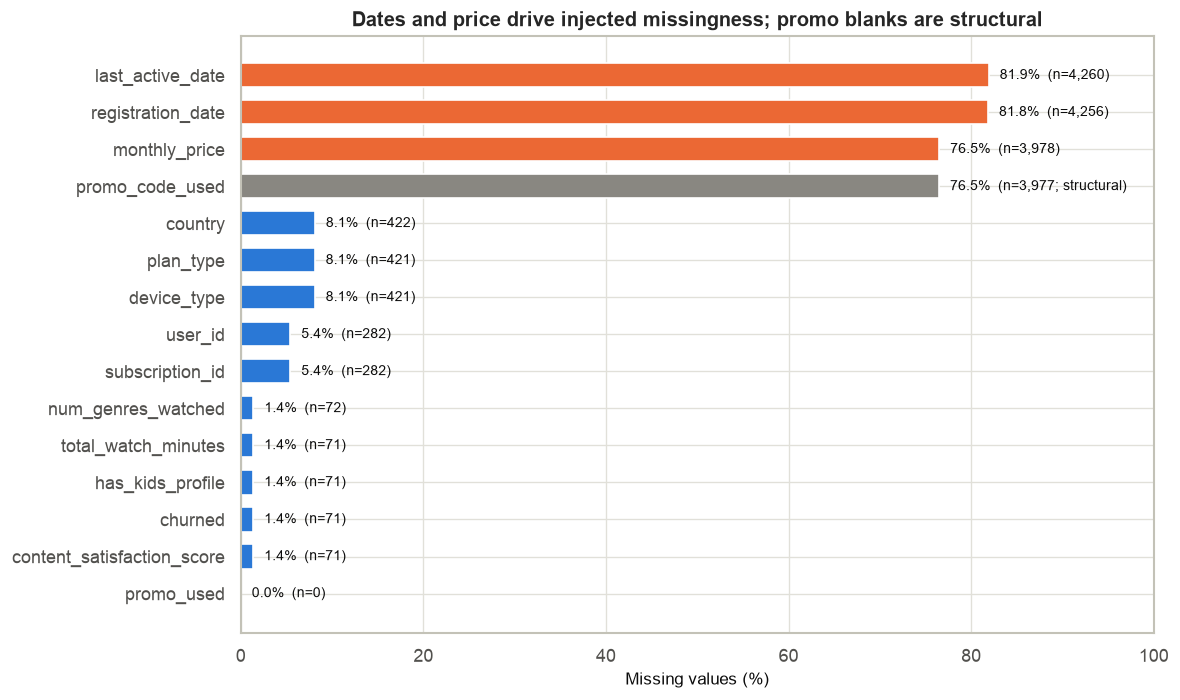

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
order = missing_table.index[::-1]
values = missing_table.loc[order, "missing_pct"] * 100
injected_high = {"registration_date", "last_active_date", "monthly_price"}
colors = [
    ORANGE if c in injected_high else GRAY if c == "promo_code_used" else BLUE
    for c in order
]
bars = ax.barh(order, values, color=colors, height=0.65)
ax.set_xlim(0, 100)
ax.set_xlabel("Missing values (%)")
ax.set_title("Dates and price drive injected missingness; promo blanks are structural")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for bar, col_name in zip(bars, order):
    count = int(missing_table.loc[col_name, "missing"])
    suffix = "; structural" if col_name == "promo_code_used" else ""
    ax.text(
        bar.get_width() + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%  (n={count:,}{suffix})",
        va="center",
        fontsize=8.5,
        color=INK,
    )
plt.tight_layout()
plt.show()

The two date columns and `monthly_price` are the high-missingness features; they
are also the columns with the lowest information density per row. `promo_code_used`
is high because most subscribers did not use a code, not because the code is
unknown — discussed next.

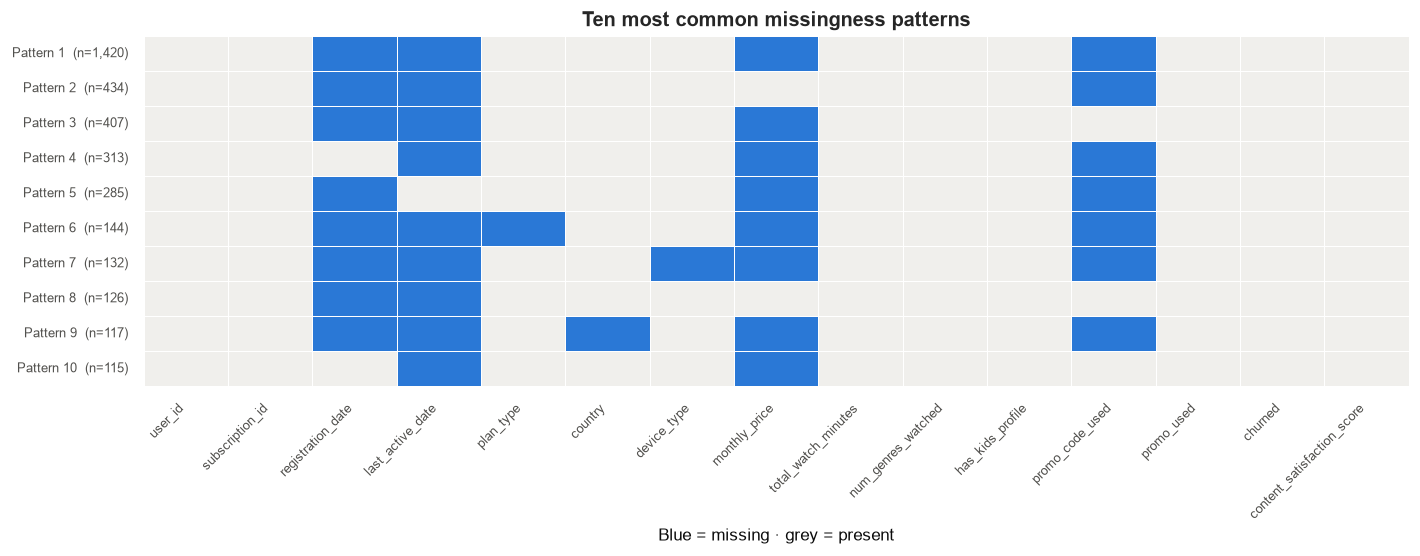

In [12]:
missing_binary = df[ANALYSIS_COLS].isna().astype(int)
pattern_strings = missing_binary.astype(str).agg("".join, axis=1)
pattern_counts = pattern_strings.value_counts().head(10)

pattern_matrix = np.array([[int(ch) for ch in pattern] for pattern in pattern_counts.index])
pattern_labels = [f"Pattern {i + 1}  (n={n:,})" for i, n in enumerate(pattern_counts.values)]

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(
    pattern_matrix,
    cmap=sns.color_palette(["#f0efec", BLUE], as_cmap=True),
    cbar=False,
    linewidths=0.6,
    linecolor="white",
    xticklabels=ANALYSIS_COLS,
    yticklabels=pattern_labels,
    ax=ax,
)
ax.set_title("Ten most common missingness patterns")
ax.set_xlabel("Blue = missing · grey = present")
ax.set_ylabel("")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

The pattern matrix confirms that missingness is spread across different column
combinations rather than concentrated in a single row-level failure. That is
consistent with independent injection at the column level.

In [13]:
valid_target = df[df["churned"].notna()].copy()
valid_target["churned"] = valid_target["churned"].astype(int)

mcar_rows = []
for col in [
    "monthly_price",
    "registration_date",
    "last_active_date",
    "plan_type",
    "country",
    "device_type",
    "total_watch_minutes",
    "content_satisfaction_score",
]:
    for churn_value, label in [(0, "Stayed"), (1, "Churned")]:
        subset = valid_target[valid_target["churned"].eq(churn_value)]
        mcar_rows.append(
            {
                "column": col,
                "churned": label,
                "n": len(subset),
                "missing_pct": subset[col].isna().mean(),
            }
        )
mcar_table = pd.DataFrame(mcar_rows).pivot(
    index="column", columns="churned", values="missing_pct"
)
mcar_table = mcar_table.assign(
    difference=mcar_table["Churned"] - mcar_table["Stayed"]
).sort_values("difference", key=np.abs, ascending=False)
display(mcar_table.style.format("{:.1%}"))

churned,Churned,Stayed,difference
column,,,
country,7.4%,8.5%,-1.1%
monthly_price,76.1%,76.8%,-0.7%
last_active_date,82.4%,81.8%,0.6%
device_type,7.9%,8.2%,-0.3%
plan_type,7.9%,8.2%,-0.3%
content_satisfaction_score,1.1%,1.3%,-0.2%
total_watch_minutes,1.4%,1.3%,0.1%
registration_date,81.8%,81.8%,-0.0%


Missingness rates are nearly identical for churned and retained subscribers. That
is consistent with **missing-at-random injection** with respect to the outcome, so
complete-case business comparisons are not obviously biased by the outcome. The
cost is statistical power, especially for price and tenure.

### Is a blank promo code “missing” or “no promo”?

This matters for Question 2. Three pieces of evidence point to **structural no-promo**:

1. A blank is the natural business encoding of “no promo used”; only 4 codes exist.
2. Promo presence varies by country (18.2%–28.1%), which is what a real acquisition
   mix looks like, not a random 76.5% erasure.
3. If 76.5% of promo values had been independently erased, the observed 23.5%
   non-blank rate would imply a near-100% true promo-usage rate — implausible for a
   streaming service. In contrast, every subscriber must have a price, so the 76.5%
   price blank rate is unambiguously injected missingness.

We therefore treat `promo_code_used = blank` as `promo_used = 0`, and we flag the
assumption in the limitations. Question 2 is answered with that encoding.

In [14]:
promo_country = (
    df.groupby("country")["promo_used"]
    .agg(["size", "mean"])
    .assign(promo_pct=lambda x: x["mean"])
    .sort_values("promo_pct", ascending=False)
)
display(promo_country.style.format({"mean": "{:.1%}", "promo_pct": "{:.1%}"}))

price_presence_by_promo = (
    df.assign(price_present=df["monthly_price"].notna())
    .groupby("promo_used")["price_present"]
    .agg(["size", "mean"])
)
display(price_presence_by_promo.style.format({"mean": "{:.1%}"}))

,size,mean,promo_pct
country,,,
Australia,441,28.1%,28.1%
Germany,505,25.3%,25.3%
UK,522,25.3%,25.3%
Brazil,463,23.5%,23.5%
USA,1209,23.4%,23.4%
Japan,461,22.3%,22.3%
Canada,716,21.1%,21.1%
France,461,18.2%,18.2%


,size,mean
promo_used,,
0,3977,23.5%
1,1223,23.5%


### Triage table

| Column / group | Missing rate | Mechanism | Decision | Rationale |
|---|---|---|---|---|
| `registration_date`, `last_active_date` | ~81% each | Injected high-rate missingness + 1970 sentinel | Keep for Q4 only; derive `account_age_days` + indicator for ML; exclude raw dates | Too sparse for raw features; `last_active_date` leaks churn timing |
| `monthly_price` | ~76% | Injected high-rate missingness | Keep in cleaned data for Q2; **exclude from ML features** | Imputing three of four values would mostly be synthetic; price is largely redundant with plan |
| `promo_code_used` | ~76% blank | Structural no-promo | Encode `promo_used` 0/1; retain code for EDA | Blank is a business category, not an unknown |
| `plan_type`, `country`, `device_type` | ~8% each | Injected categorical missingness | Encode missing as explicit `Unknown` category | Preserves the missingness signal without fabricating a modal category |
| `total_watch_minutes`, `num_genres_watched`, `content_satisfaction_score`, `has_kids_profile` | <2% after sentinel nulling | Injected sentinel corruption | Median / most-frequent imputation **plus missing indicator** | Small enough to impute credibly; indicators preserve the corruption flag |
| `churned` (target) | 64 rows (1.3% of unique records) | Corrupted and not recoverable from duplicates | Exclude from supervised learning | Never impute an outcome |
| `user_id`, `subscription_id` | 278 rows with both missing | Injected ID gaps | Keep with `id_missing` flag; drop from ML | Identifiers have no predictive meaning and would leak row identity |

**Principle:** imputation is a model-preprocessing step, not a data-cleaning step.
`dataset_cleaned.csv` keeps `NaN` where the truth is unknown; the model pipeline in
Part 6 learns imputation values from `X_train` only.

---
# Part 4 — Deduplication & Outlier Detective Work

Two independent data-quality stories meet here:

1. **Duplicate records** that are not exact copies. One copy has the price, another
   has the dates, a third has the target. Dropping the “extra” row destroys usable
   information; merging recovers it.
2. **Sentinel outliers** that look like extreme users but are repeated constants
   from a corruption process. IQR would flag both sentinels and legitimate heavy
   viewers, so we use domain rules to classify and null only the impossible values.

In [15]:
content_cols = [
    "registration_date",
    "plan_type",
    "country",
    "device_type",
    "monthly_price",
    "total_watch_minutes",
    "num_genres_watched",
    "has_kids_profile",
    "promo_code_used",
    "last_active_date",
    "churned",
    "content_satisfaction_score",
]

fingerprint = (
    df[content_cols].astype("string").fillna("<NA>").agg("|".join, axis=1)
)
df["_merge_key"] = np.where(
    df["user_id"].notna(),
    "S" + df["user_id"].astype("string"),
    "F" + fingerprint,
)
df["_n_missing"] = df[content_cols].isna().sum(axis=1)

group_sizes = df.groupby("_merge_key").size()
duplicate_groups = int((group_sizes > 1).sum())
duplicate_rows = int((group_sizes - 1).clip(lower=0).sum())

duplicate_overview = pd.DataFrame(
    [
        {"check": "Rows before dedup", "value": len(df)},
        {"check": "Duplicate groups (size > 1)", "value": duplicate_groups},
        {"check": "Rows removable by merging", "value": duplicate_rows},
        {"check": "Groups of size 2", "value": int((group_sizes == 2).sum())},
        {"check": "Groups of size 3", "value": int((group_sizes == 3).sum())},
        {"check": "Rows with both IDs missing", "value": int(df["user_id"].isna().sum())},
        {"check": "Exact duplicate rows (ignoring IDs)", "value": int(df.duplicated(subset=content_cols).sum())},
    ]
)
display(duplicate_overview)

,check,value
0,Rows before dedup,5200
1,Duplicate groups (size > 1),214
2,Rows removable by merging,223
3,Groups of size 2,205
4,Groups of size 3,9
5,Rows with both IDs missing,282
6,Exact duplicate rows (ignoring IDs),70


### A representative duplicate group

The rows below share the same normalized subscription. The first copy has a price
but no dates; the second copy has the dates. A `drop_duplicates()` call would keep
one and lose the other. A coalescing merge keeps both.

In [16]:
example_key = None
for candidate, grp in df.groupby("_merge_key", sort=False):
    if len(grp) < 2:
        continue
    if grp["monthly_price"].notna().any() and grp["monthly_price"].isna().any():
        example_key = candidate
        break
if example_key is None:
    example_key = group_sizes[group_sizes > 1].index.to_series().iloc[0]
example_cols = [
    "user_id",
    "subscription_id",
    "registration_date",
    "last_active_date",
    "monthly_price",
    "total_watch_minutes",
    "churned",
    "content_satisfaction_score",
]
display(df.loc[df["_merge_key"].eq(example_key), example_cols])

,user_id,subscription_id,registration_date,last_active_date,monthly_price,total_watch_minutes,churned,content_satisfaction_score
36,4304,SUB_0004304,NaT,NaT,NaN,3739.0,0,2.0
2270,4304,SUB_0004304,NaT,NaT,15.72,3739.0,0,2.0


In [17]:
conflict_groups = 0
for _, grp in df.groupby("_merge_key", sort=False):
    if len(grp) < 2:
        continue
    for col in content_cols:
        if grp[col].dropna().nunique() > 1:
            conflict_groups += 1
            break

# Which fields were recovered from a secondary copy?
recovered_fields = {}
for _, grp in df.groupby("_merge_key", sort=False):
    if len(grp) < 2:
        continue
    grp = grp.sort_values("_n_missing", kind="stable")
    first = grp.iloc[0]
    for col in content_cols:
        if pd.isna(first[col]) and grp[col].notna().any():
            recovered_fields[col] = recovered_fields.get(col, 0) + 1

recovered_table = (
    pd.DataFrame(
        {"column": list(recovered_fields.keys()), "duplicate_groups_recovered": list(recovered_fields.values())}
    )
    .sort_values("duplicate_groups_recovered", ascending=False)
)
print(f"Groups with at least one true non-null conflict: {conflict_groups}")
display(recovered_table)

Groups with at least one true non-null conflict: 32


,column,duplicate_groups_recovered
4,monthly_price,11
0,registration_date,10
1,last_active_date,8
3,churned,5
6,plan_type,3
5,promo_code_used,2
2,has_kids_profile,1
7,content_satisfaction_score,1
8,num_genres_watched,1


In [18]:
group_corruption = df.groupby("_merge_key")["n_corrupted_cells"].max()

merged = (
    df.sort_values("_n_missing", kind="stable")
    .groupby("_merge_key", as_index=False, sort=False)
    .first()
)
merged = merged.merge(group_sizes.rename("records_merged"), on="_merge_key", how="left")
merged = merged.merge(
    group_corruption.rename("source_corrupted_cells"), on="_merge_key", how="left"
)
merged["n_corrupted_cells"] = merged["source_corrupted_cells"]
merged = merged.drop(columns=["_merge_key", "_n_missing", "source_corrupted_cells"])

# Recompute lifecycle fields after the merge.
merged["tenure_days"] = (
    merged["last_active_date"] - merged["registration_date"]
).dt.days
merged.loc[~merged["tenure_days"].between(0, 3650), "tenure_days"] = np.nan
merged["id_missing"] = merged["user_id"].isna()

print(f"Rows before merge: {len(df):,}")
print(f"Rows after merge:  {len(merged):,}")
print(f"Rows removed:      {len(df) - len(merged):,}")

target_corrupted_before = int(df["churned"].isna().sum())
target_missing_after = int(merged["churned"].isna().sum())
print(
    f"\nCorrupted target rows before merge: {target_corrupted_before}; "
    f"after merge: {target_missing_after}; "
    f"repaired by duplicate coalescing: {target_corrupted_before - target_missing_after}"
)
print(f"Unique records with both IDs missing: {int(merged['id_missing'].sum()):,}")

display(merged.head(3))

Rows before merge: 5,200
Rows after merge:  4,977
Rows removed:      223

Corrupted target rows before merge: 71; after merge: 64; repaired by duplicate coalescing: 7
Unique records with both IDs missing: 278


,user_id,subscription_id,registration_date,plan_type,country,device_type,monthly_price,total_watch_minutes,num_genres_watched,has_kids_profile,promo_code_used,last_active_date,churned,content_satisfaction_score,user_id_original,subscription_id_original,id_status,promo_used,tenure_days,watch_corrupted,genres_corrupted,sat_corrupted,kids_corrupted,churn_corrupted,n_corrupted_cells,records_merged,id_missing
0,4916,SUB_0004916,2020-10-09,Premium,Brazil,Mobile,19.75,0.0,2.0,0,STREAMFREE,2023-09-15,0,5.0,4916,SUB_0004916,valid,1,1071.0,False,False,False,False,False,0,1,False
1,241,SUB_0000241,2023-03-26,Premium,Brazil,Smart TV,20.16,5240.0,8.0,0,SPRING20,2023-10-13,0,0.0,241,SUB_0000241,valid,1,201.0,False,False,False,False,False,0,1,False
2,2724,SUB_0002724,2020-05-17,Standard,Australia,Tablet,14.75,5592.0,5.0,0,WELCOME10,2020-10-09,0,3.0,2724,SUB_0002724,valid,1,145.0,False,False,False,False,False,0,1,False


### The sentinel palette

The exact repetition of unusual values is the decisive evidence. These are not
tails of a real distribution; they are a small palette of injected constants:

- **Watch minutes:** 161,050 appears 26 times and 322,100 appears 21 times.
- **Genres:** 187 appears 26 times and 375 appears 21 times.
- **Satisfaction:** 62 appears 26 times and 125 appears 21 times.
- **Binary flags:** 12 appears 26 times and 25 appears 21 times.
- **User IDs:** 62,500 and 125,000 appear repeatedly, plus negative IDs.

The matching counts across columns (26 and 21) show a coordinated injection
process. The correct treatment is to null the values, not to infer that a
subscriber watched 322,100 minutes.

In [19]:
sentinel_table = pd.DataFrame(
    [
        {"column": "total_watch_minutes", "raw_sentinel_values": "−8,272; 161,050; 322,100", "counts": "24 negative; 26 × 161,050; 21 × 322,100", "valid_rule": "0–44,640"},
        {"column": "num_genres_watched", "raw_sentinel_values": "negatives; 187; 375", "counts": "25 negative; 26 × 187; 21 × 375", "valid_rule": "0–20"},
        {"column": "content_satisfaction_score", "raw_sentinel_values": "negatives; 62; 125", "counts": "24 negative; 26 × 62; 21 × 125", "valid_rule": "0–5"},
        {"column": "has_kids_profile", "raw_sentinel_values": "12; 25; −50; −1", "counts": "26 × 12; 21 × 25; 24 other", "valid_rule": "0 / 1"},
        {"column": "churned", "raw_sentinel_values": "12; 25; −50; −1", "counts": "26 × 12; 21 × 25; 24 other", "valid_rule": "0 / 1"},
        {"column": "user_id", "raw_sentinel_values": "negative; 62,500; 125,000", "counts": "24 negative; 47 above 5,000", "valid_rule": "1–5,000"},
        {"column": "dates", "raw_sentinel_values": "1970-01-01", "counts": "39 in each date column", "valid_rule": "not 1970"},
    ]
)
display(sentinel_table)

,column,raw_sentinel_values,counts,valid_rule
0,total_watch_minutes,"−8,272; 161,050; 322,100","24 negative; 26 × 161,050; 21 × 322,100","0–44,640"
1,num_genres_watched,negatives; 187; 375,25 negative; 26 × 187; 21 × 375,0–20
2,content_satisfaction_score,negatives; 62; 125,24 negative; 26 × 62; 21 × 125,0–5
3,has_kids_profile,12; 25; −50; −1,26 × 12; 21 × 25; 24 other,0 / 1
4,churned,12; 25; −50; −1,26 × 12; 21 × 25; 24 other,0 / 1
5,user_id,"negative; 62,500; 125,000","24 negative; 47 above 5,000","1–5,000"
6,dates,1970-01-01,39 in each date column,not 1970


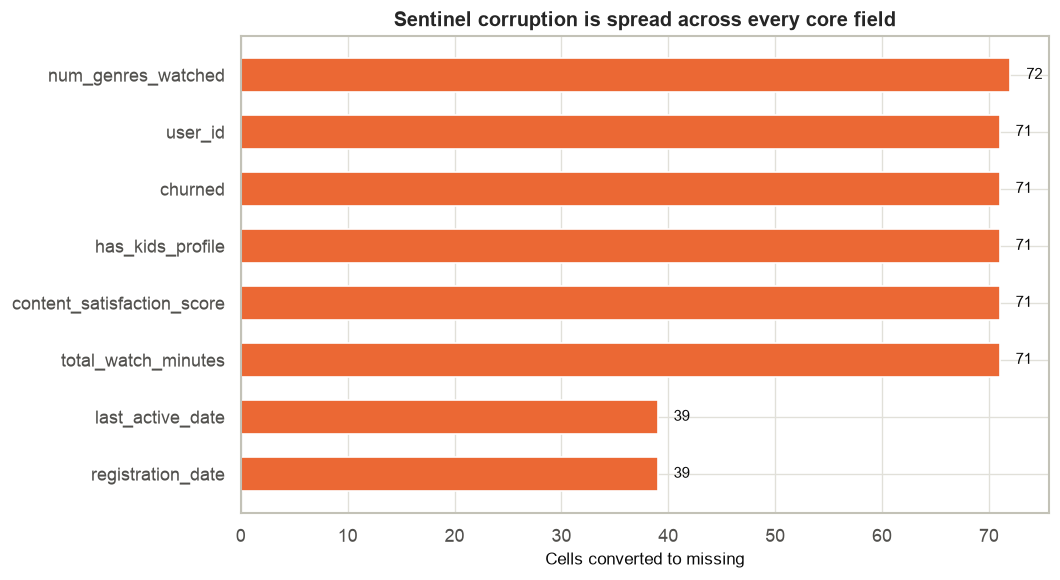

In [20]:
invalid_counts = pd.Series(
    {
        "total_watch_minutes": int(df["watch_corrupted"].sum()),
        "num_genres_watched": int(df["genres_corrupted"].sum()),
        "content_satisfaction_score": int(df["sat_corrupted"].sum()),
        "has_kids_profile": int(df["kids_corrupted"].sum()),
        "churned": int(df["churn_corrupted"].sum()),
        "user_id": int((uid_numeric.notna() & ~uid_numeric.between(ID_MIN, ID_MAX)).sum()),
        "registration_date": 39,
        "last_active_date": 39,
    }
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(invalid_counts.index, invalid_counts.values, color=ORANGE, height=0.6)
ax.set_xlabel("Cells converted to missing")
ax.set_title("Sentinel corruption is spread across every core field")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for bar, value in zip(bars, invalid_counts.values):
    ax.text(
        bar.get_width() + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=9,
        color=INK,
    )
plt.tight_layout()
plt.show()

In [21]:
raw_watch = pd.to_numeric(raw["total_watch_minutes"], errors="coerce")
raw_genres = pd.to_numeric(raw["num_genres_watched"], errors="coerce")
raw_sat = pd.to_numeric(raw["content_satisfaction_score"], errors="coerce")

before_after = pd.DataFrame(
    [
        {
            "field": "total_watch_minutes",
            "raw_min": raw_watch.min(),
            "raw_median": raw_watch.median(),
            "raw_max": raw_watch.max(),
            "clean_min": merged["total_watch_minutes"].min(),
            "clean_median": merged["total_watch_minutes"].median(),
            "clean_max": merged["total_watch_minutes"].max(),
        },
        {
            "field": "num_genres_watched",
            "raw_min": raw_genres.min(),
            "raw_median": raw_genres.median(),
            "raw_max": raw_genres.max(),
            "clean_min": merged["num_genres_watched"].min(),
            "clean_median": merged["num_genres_watched"].median(),
            "clean_max": merged["num_genres_watched"].max(),
        },
        {
            "field": "content_satisfaction_score",
            "raw_min": raw_sat.min(),
            "raw_median": raw_sat.median(),
            "raw_max": raw_sat.max(),
            "clean_min": merged["content_satisfaction_score"].min(),
            "clean_median": merged["content_satisfaction_score"].median(),
            "clean_max": merged["content_satisfaction_score"].max(),
        },
    ]
)
display(before_after.style.format({"raw_min": "{:.1f}", "raw_median": "{:.1f}", "raw_max": "{:,.1f}", "clean_min": "{:.1f}", "clean_median": "{:.1f}", "clean_max": "{:,.1f}"}))

,field,raw_min,raw_median,raw_max,clean_min,clean_median,clean_max
0,total_watch_minutes,-8272.0,4754.5,"322,100.0",0.0,4750.0,"12,884.0"
1,num_genres_watched,-9.0,5.0,375.0,0.0,5.0,15.0
2,content_satisfaction_score,-5.0,3.0,125.0,0.0,3.0,5.0


### Outlier verdict

- **Sentinel values are not genuine extremes.** They are exact constants, often
  repeated 21–26 times, and they violate physical or scale bounds.
- **They are converted to `NaN` before deduplication**, so a corrupted copy cannot
  win a merge conflict against a clean copy.
- **We do not winsorize.** A value of 322,100 minutes is not “a very engaged user”;
  it is a data-quality event. Replacing it with a percentile would fabricate a
  plausible observation.
- **Legitimate zeros are retained.** 0 watch minutes and 0 genres watched are valid
  states, not sentinels. They will be modelled explicitly with zero-inflation flags.

### Cleaned dataset export

The cleaned table keeps the resolved identifiers, the coerced business fields,
`tenure_days`, and two audit columns (`records_merged`, `n_corrupted_cells`). It
intentionally retains `NaN` for unknown targets and missing dates; imputation is a
modelling decision, not a cleaning one.

In [22]:
export_cols = [
    "user_id",
    "subscription_id",
    "registration_date",
    "last_active_date",
    "plan_type",
    "country",
    "device_type",
    "monthly_price",
    "total_watch_minutes",
    "num_genres_watched",
    "has_kids_profile",
    "promo_code_used",
    "promo_used",
    "churned",
    "content_satisfaction_score",
    "tenure_days",
    "id_missing",
    "records_merged",
    "n_corrupted_cells",
]
cleaned = merged[export_cols].copy()
cleaned.to_csv("dataset_cleaned.csv", index=False)

print(f"dataset_cleaned.csv → {cleaned.shape[0]:,} rows × {cleaned.shape[1]} columns")
display(cleaned.head(5))

dataset_cleaned.csv → 4,977 rows × 19 columns


,user_id,subscription_id,registration_date,last_active_date,plan_type,country,device_type,monthly_price,total_watch_minutes,num_genres_watched,has_kids_profile,promo_code_used,promo_used,churned,content_satisfaction_score,tenure_days,id_missing,records_merged,n_corrupted_cells
0,4916,SUB_0004916,2020-10-09,2023-09-15,Premium,Brazil,Mobile,19.75,0.0,2.0,0,STREAMFREE,1,0,5.0,1071.0,False,1,0
1,241,SUB_0000241,2023-03-26,2023-10-13,Premium,Brazil,Smart TV,20.16,5240.0,8.0,0,SPRING20,1,0,0.0,201.0,False,1,0
2,2724,SUB_0002724,2020-05-17,2020-10-09,Standard,Australia,Tablet,14.75,5592.0,5.0,0,WELCOME10,1,0,3.0,145.0,False,1,0
3,3241,SUB_0003241,2020-07-18,2021-02-12,Standard,Australia,Mobile,15.32,6267.0,1.0,0,HOLIDAYDEAL,1,0,5.0,209.0,False,2,0
4,421,SUB_0000421,2020-06-03,2023-04-15,Standard,USA,Mobile,15.12,3411.0,6.0,0,STREAMFREE,1,0,2.0,1046.0,False,1,0


### Cleaning ledger

| Stage | Rows / cells | Decision |
|---|---|---|
| Raw file | 5,200 rows × 14 columns | Preserve as `raw` |
| Whitespace + blank normalization | all text columns | Strip, blank → `NA` |
| Plan canonicalization | 16 raw spellings → 3 tiers + missing | `startswith` mapping |
| ID repair | 233 from subscription, 382 from user, 36 conflicts | Prefer subscription; else user |
| ID gaps | 282 rows with both IDs invalid, 278 after merge | Keep with `id_missing` |
| Sentinel nulling | 71 watch, 72 genres, 71 satisfaction, 71 kids, 71 churned; 316 rows affected | Domain-invalid → `NaN` |
| Date sentinel | 78 cells (39 + 39) | `1970-01-01` → `NaT` |
| Duplicate merge | 223 duplicate rows collapsed into 214 groups | Coalesce non-null values |
| Target repair | 7 corrupted targets recovered from duplicates; 64 remain missing | Exclude missing targets from ML |
| Final cleaned table | **4,977 unique subscription records** | `dataset_cleaned.csv` |

---
# Part 5 — The Five Business Questions

All five analyses use the **deduplicated, target-valid** table (`4,913` rows, 33.5%
churn). Confidence intervals are Wilson score intervals for proportions. Tests are
two-sided. The one-sentence executive takeaway follows each chart.

In [23]:
eda = merged[merged["churned"].notna()].copy()
eda["churned"] = eda["churned"].astype(int)

print(f"Business analysis population: {len(eda):,} records")
print(f"Overall churn rate: {eda['churned'].mean():.2%}")
print(f"Rows excluded for missing/corrupted target: {int(merged['churned'].isna().sum()):,}")

Business analysis population: 4,913 records
Overall churn rate: 33.54%
Rows excluded for missing/corrupted target: 64


## Question 1 — Churn performance by subscription plan

**Business question:** What is the churn rate for each plan, and which tier shows
the highest or lowest churn?

**Method:** group by `plan_type`, compute churn counts and Wilson intervals, test
independence with a chi-square test, and compare the observed rates.

In [24]:
q1 = (
    eda.groupby("plan_type", observed=True)["churned"]
    .agg(n="size", churned="sum")
    .reindex(PLAN_ORDER)
)
q1["churn_rate"] = q1["churned"] / q1["n"]
q1[["ci_low", "ci_high"]] = [
    wilson_ci(int(successes), int(n)) for successes, n in zip(q1["churned"], q1["n"])
]
display(q1.style.format({"churn_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))

q1_chi2, q1_p, q1_dof, _ = stats.chi2_contingency(
    pd.crosstab(eda["plan_type"], eda["churned"])
)
print(f"Chi-square test of independence: χ² = {q1_chi2:.2f}, df = {q1_dof}, p = {q1_p:.3e}")
print(f"Analysis rows excluded from Q1 for missing plan_type: {int(eda['plan_type'].isna().sum()):,}")

,n,churned,churn_rate,ci_low,ci_high
plan_type,,,,,
Basic,1822,782,42.9%,40.7%,45.2%
Standard,1776,479,27.0%,25.0%,29.1%
Premium,915,256,28.0%,25.2%,31.0%


Chi-square test of independence: χ² = 118.86, df = 2, p = 1.551e-26
Analysis rows excluded from Q1 for missing plan_type: 400


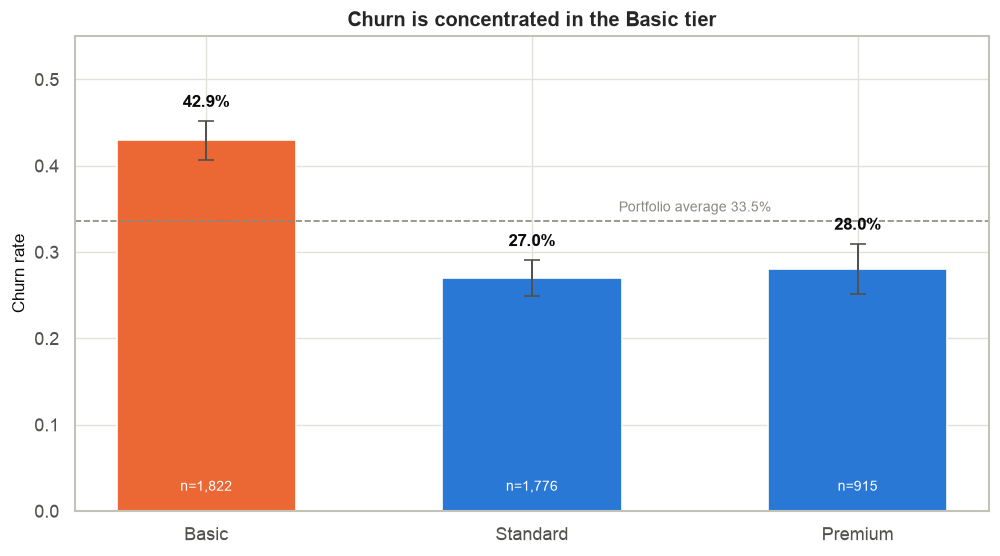

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [ORANGE if plan == q1["churn_rate"].idxmax() else BLUE for plan in q1.index]
yerr = np.vstack(
    [
        q1["churn_rate"] - q1["ci_low"],
        q1["ci_high"] - q1["churn_rate"],
    ]
)
bars = ax.bar(
    q1.index,
    q1["churn_rate"],
    color=colors,
    width=0.55,
    yerr=yerr,
    capsize=5,
    error_kw={"ecolor": "#52514e", "lw": 1.2},
)
ax.set_ylim(0, 0.55)
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
ax.set_title("Churn is concentrated in the Basic tier")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.axhline(eda["churned"].mean(), color=GRAY, linestyle="--", linewidth=1)
ax.text(
    1.5,
    eda["churned"].mean() + 0.008,
    f"Portfolio average {eda['churned'].mean():.1%}",
    ha="center",
    va="bottom",
    fontsize=8.5,
    color=GRAY,
)
for bar, rate, n, upper in zip(bars, q1["churn_rate"], q1["n"], q1["ci_high"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        upper + 0.012,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        0.02,
        f"n={int(n):,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color="white",
    )
plt.tight_layout()
plt.show()

**Executive takeaway:** *Basic subscribers churn at 42.9%, roughly 15–16 percentage
points above Standard (27.0%) and Premium (28.0%), making the entry tier the
clearest retention priority.*

The chi-square test is decisive (p < 0.001). Because Basic is also the largest tier,
even a modest retention improvement there would move the portfolio churn rate more
than an equivalent improvement in either premium tier. The next diagnostic is
whether this is a price/value perception issue or a product-content issue; the
satisfaction analysis in Question 3 suggests the latter is actionable. The 400
analysis rows with a missing plan tier (8.1%) are excluded from the tier comparison.

## Question 2 — Evaluating promotional campaign impact

**Business question:** Do subscribers who used a promo code differ in churn or
average monthly price from those who did not?

**Method:** compare churn proportions with Wilson intervals and a chi-square test;
compare the observed price distributions with Welch’s t-test and a Mann–Whitney U
test; repeat the churn comparison within each plan to control for plan mix. Only
24.3% of records have an observed price, so the price comparison is explicitly
labelled as a complete-case analysis.

In [26]:
q2 = (
    eda.groupby("promo_used")
    .agg(n=("churned", "size"), churned=("churned", "sum"))
    .rename(index={0: "No promo", 1: "Promo"})
)
q2["churn_rate"] = q2["churned"] / q2["n"]
q2[["ci_low", "ci_high"]] = [
    wilson_ci(int(successes), int(n)) for successes, n in zip(q2["churned"], q2["n"])
]

q2_chi2, q2_p, q2_dof, _ = stats.chi2_contingency(
    pd.crosstab(eda["promo_used"], eda["churned"])
)

price_observed = eda[eda["monthly_price"].notna()].copy()
price_by_promo = price_observed.groupby("promo_used")["monthly_price"].agg(
    ["size", "mean", "median", "std"]
)
price_by_promo.index = ["No promo", "Promo"]
welch = stats.ttest_ind(
    price_observed.loc[price_observed["promo_used"].eq(1), "monthly_price"],
    price_observed.loc[price_observed["promo_used"].eq(0), "monthly_price"],
    equal_var=False,
)
mwu = stats.mannwhitneyu(
    price_observed.loc[price_observed["promo_used"].eq(1), "monthly_price"],
    price_observed.loc[price_observed["promo_used"].eq(0), "monthly_price"],
)

display(q2.style.format({"churn_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))
display(price_by_promo.style.format({"mean": "{:.2f}", "median": "{:.2f}", "std": "{:.2f}"}))
print(
    f"Churn chi-square: χ² = {q2_chi2:.3f}, df = {q2_dof}, p = {q2_p:.3f}\n"
    f"Price Welch t-test: t = {welch.statistic:.3f}, p = {welch.pvalue:.3f}\n"
    f"Price Mann–Whitney U: U = {mwu.statistic:.0f}, p = {mwu.pvalue:.3f}"
)

q2_plan = (
    eda.groupby(["plan_type", "promo_used"], observed=True)["churned"]
    .agg(n="size", churn="mean")
    .reset_index()
    .pivot(index="plan_type", columns="promo_used", values="churn")
    .reindex(PLAN_ORDER)
)

,n,churned,churn_rate,ci_low,ci_high
promo_used,,,,,
No promo,3746,1259,33.6%,32.1%,35.1%
Promo,1167,389,33.3%,30.7%,36.1%


,size,mean,median,std
No promo,906,13.81,14.59,3.71
Promo,286,13.96,14.68,3.81


Churn chi-square: χ² = 0.019, df = 1, p = 0.890
Price Welch t-test: t = 0.563, p = 0.573
Price Mann–Whitney U: U = 131309, p = 0.730


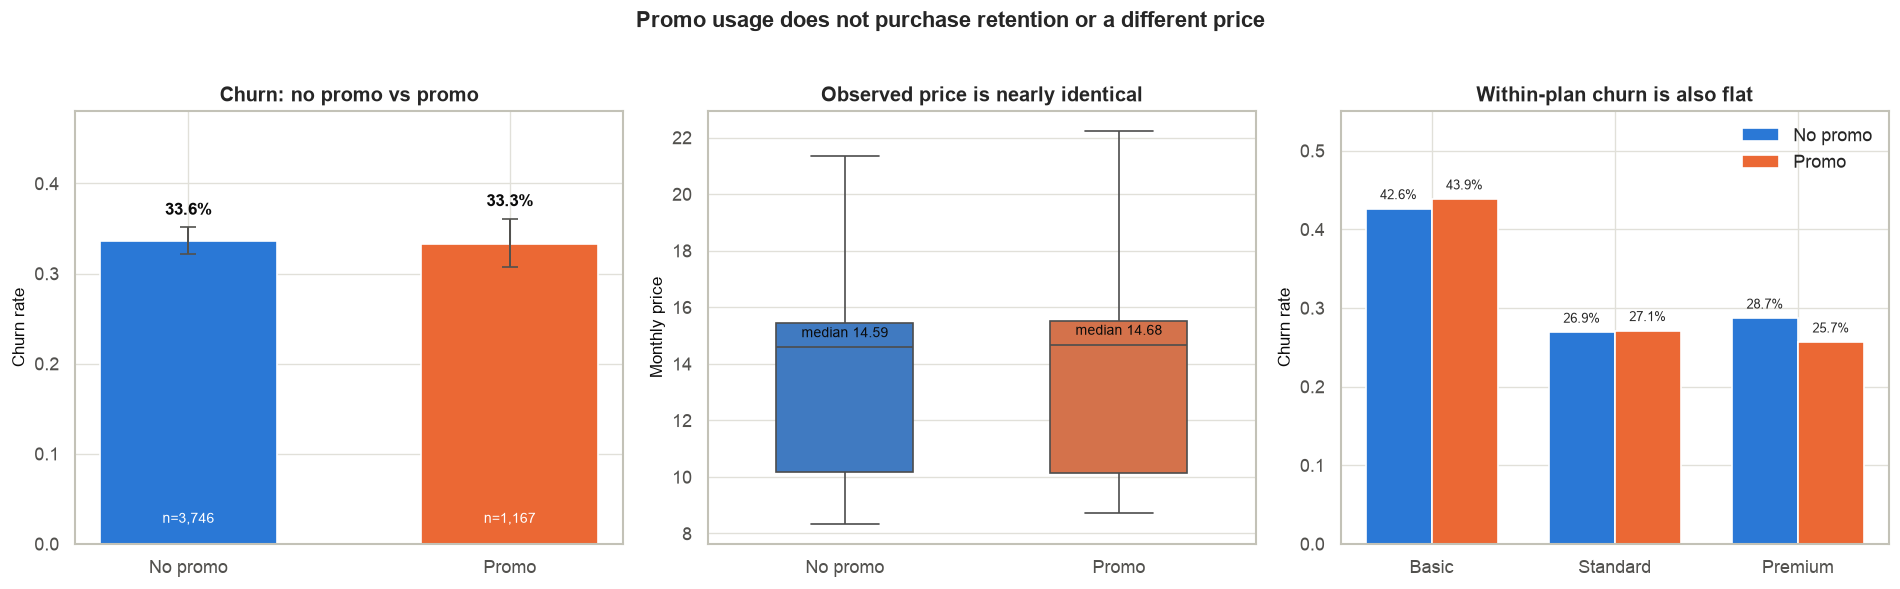

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel 1: overall churn by promo
ax = axes[0]
yerr = np.vstack(
    [q2["churn_rate"] - q2["ci_low"], q2["ci_high"] - q2["churn_rate"]]
)
bars = ax.bar(
    q2.index,
    q2["churn_rate"],
    color=[BLUE, ORANGE],
    width=0.55,
    yerr=yerr,
    capsize=5,
    error_kw={"ecolor": "#52514e", "lw": 1.2},
)
ax.set_ylim(0, 0.48)
ax.set_ylabel("Churn rate")
ax.set_title("Churn: no promo vs promo")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for bar, rate, n, upper in zip(bars, q2["churn_rate"], q2["n"], q2["ci_high"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        upper + 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        0.02,
        f"n={int(n):,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color="white",
    )

# Panel 2: observed price distribution
ax = axes[1]
sns.boxplot(
    data=price_observed,
    x="promo_used",
    y="monthly_price",
    hue="promo_used",
    palette=[BLUE, ORANGE],
    width=0.5,
    showfliers=False,
    ax=ax,
    legend=False,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No promo", "Promo"])
ax.set_xlabel("")
ax.set_ylabel("Monthly price")
ax.set_title("Observed price is nearly identical")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for i, (label, row) in enumerate(price_by_promo.iterrows()):
    ax.text(i, row["median"] + 0.35, f"median {row['median']:.2f}", ha="center", fontsize=8.5, color=INK)

# Panel 3: churn by plan and promo
ax = axes[2]
x = np.arange(len(PLAN_ORDER))
width = 0.36
ax.bar(x - width / 2, q2_plan[0], width=width, color=BLUE, label="No promo")
ax.bar(x + width / 2, q2_plan[1], width=width, color=ORANGE, label="Promo")
ax.set_xticks(x)
ax.set_xticklabels(PLAN_ORDER)
ax.set_xlabel("")
ax.set_ylabel("Churn rate")
ax.set_title("Within-plan churn is also flat")
ax.set_ylim(0, 0.55)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
for xi, plan in zip(x, PLAN_ORDER):
    ax.text(xi - width / 2, q2_plan.loc[plan, 0] + 0.012, f"{q2_plan.loc[plan, 0]:.1%}", ha="center", fontsize=8)
    ax.text(xi + width / 2, q2_plan.loc[plan, 1] + 0.012, f"{q2_plan.loc[plan, 1]:.1%}", ha="center", fontsize=8)

fig.suptitle("Promo usage does not purchase retention or a different price", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Executive takeaway:** *Promo users and non-promo users churn at statistically
indistinguishable rates (33.3% vs 33.6%, p = 0.89) and pay almost identical monthly
prices (median 14.68 vs 14.59), so this binary promo flag shows no retention or
pricing benefit.*

The within-plan view rules out a Simpson’s paradox: Basic promo users churn slightly
more (43.9% vs 42.6%), Premium promo users slightly less (25.7% vs 28.7%), and
Standard is flat. The price comparison is complete-case only (1,192 observed
prices), so it is less precise than the churn comparison, but the point estimate is
essentially zero. If the business wants to evaluate promotions properly, it should
record the discount depth and the acquisition channel, not just a binary code flag.
The unavoidable caveat is the missingness in `promo_code_used`: if blanks were
missing rather than “no promo”, the observed null would be diluted toward zero.

## Question 3 — Identifying high-churn risk profiles by engagement

**Business question:** Are watch time, genre breadth, or satisfaction associated
with churn? Do lower values imply higher churn probability?

**Method:** examine the full satisfaction-score curve (not just a single correlation),
bin watch time and genre count, compute Spearman correlations, and test the
satisfaction signal within each plan. The exact-score view is essential because the
relationship is strongly non-linear.

In [28]:
q3_sat = (
    eda.groupby("content_satisfaction_score")["churned"]
    .agg(n="size", churned="sum")
)
q3_sat["churn_rate"] = q3_sat["churned"] / q3_sat["n"]
q3_sat[["ci_low", "ci_high"]] = [
    wilson_ci(int(s), int(n)) for s, n in zip(q3_sat["churned"], q3_sat["n"])
]

watch_frame = eda[eda["total_watch_minutes"].notna()].copy()
watch_frame["watch_bin"] = pd.cut(
    watch_frame["total_watch_minutes"],
    bins=[-0.1, 0, 1_000, 3_000, 5_000, 7_000, 10_000, 20_000, 44_640],
    labels=["0", "1–1k", "1k–3k", "3k–5k", "5k–7k", "7k–10k", "10k–20k", "20k+"],
)
q3_watch = watch_frame.groupby("watch_bin", observed=True)["churned"].agg(n="size", churn="mean")

genre_frame = eda[eda["num_genres_watched"].notna()].copy()
genre_frame["genre_bin"] = pd.cut(
    genre_frame["num_genres_watched"],
    bins=[-0.1, 0, 2, 5, 8, 11, 20],
    labels=["0", "1–2", "3–5", "6–8", "9–11", "12+"],
)
q3_genre = genre_frame.groupby("genre_bin", observed=True)["churned"].agg(n="size", churn="mean")

sat1 = eda[eda["content_satisfaction_score"].eq(1)]["churned"]
sat_rest = eda[eda["content_satisfaction_score"].ne(1) & eda["content_satisfaction_score"].notna()]["churned"]
sat1_rr = sat1.mean() / sat_rest.mean()
sat1_chi2, sat1_p, _, _ = stats.chi2_contingency(
    [[sat1.sum(), len(sat1) - sat1.sum()], [sat_rest.sum(), len(sat_rest) - sat_rest.sum()]]
)

spearman_watch = stats.spearmanr(
    eda.loc[eda["total_watch_minutes"].notna(), "churned"],
    eda.loc[eda["total_watch_minutes"].notna(), "total_watch_minutes"],
)
spearman_genres = stats.spearmanr(
    eda.loc[eda["num_genres_watched"].notna(), "churned"],
    eda.loc[eda["num_genres_watched"].notna(), "num_genres_watched"],
)
spearman_sat = stats.spearmanr(
    eda.loc[eda["content_satisfaction_score"].notna(), "churned"],
    eda.loc[eda["content_satisfaction_score"].notna(), "content_satisfaction_score"],
)

display(q3_sat.style.format({"churn_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))
display(q3_watch.style.format({"churn": "{:.1%}"}))
display(q3_genre.style.format({"churn": "{:.1%}"}))
print(
    f"Satisfaction = 1 vs rest: {sat1.mean():.1%} vs {sat_rest.mean():.1%}; "
    f"risk ratio = {sat1_rr:.2f}; χ² p = {sat1_p:.3e}"
)
print(
    f"Spearman churn vs watch: ρ = {spearman_watch.statistic:.3f} (p = {spearman_watch.pvalue:.3f})\n"
    f"Spearman churn vs genres: ρ = {spearman_genres.statistic:.3f} (p = {spearman_genres.pvalue:.3f})\n"
    f"Spearman churn vs satisfaction: ρ = {spearman_sat.statistic:.3f} (p = {spearman_sat.pvalue:.3e})"
)

,n,churned,churn_rate,ci_low,ci_high
content_satisfaction_score,,,,,
0.000000,388,122,31.4%,27.0%,36.2%
1.000000,864,596,69.0%,65.8%,72.0%
2.000000,923,229,24.8%,22.1%,27.7%
3.000000,873,215,24.6%,21.9%,27.6%
4.000000,920,248,27.0%,24.2%,29.9%
5.000000,884,219,24.8%,22.0%,27.7%


,n,churn
watch_bin,,
0,451,34.4%
1–1k,66,31.8%
1k–3k,602,30.9%
3k–5k,1512,33.0%
5k–7k,1501,34.1%
7k–10k,694,35.0%
10k–20k,24,33.3%


,n,churn
genre_bin,,
0,377,31.8%
1–2,585,34.7%
3–5,2174,33.6%
6–8,1402,33.0%
9–11,287,33.1%
12+,25,48.0%


Satisfaction = 1 vs rest: 69.0% vs 25.9%; risk ratio = 2.66; χ² p = 4.138e-130
Spearman churn vs watch: ρ = 0.015 (p = 0.285)
Spearman churn vs genres: ρ = -0.001 (p = 0.937)
Spearman churn vs satisfaction: ρ = -0.206 (p = 1.465e-47)


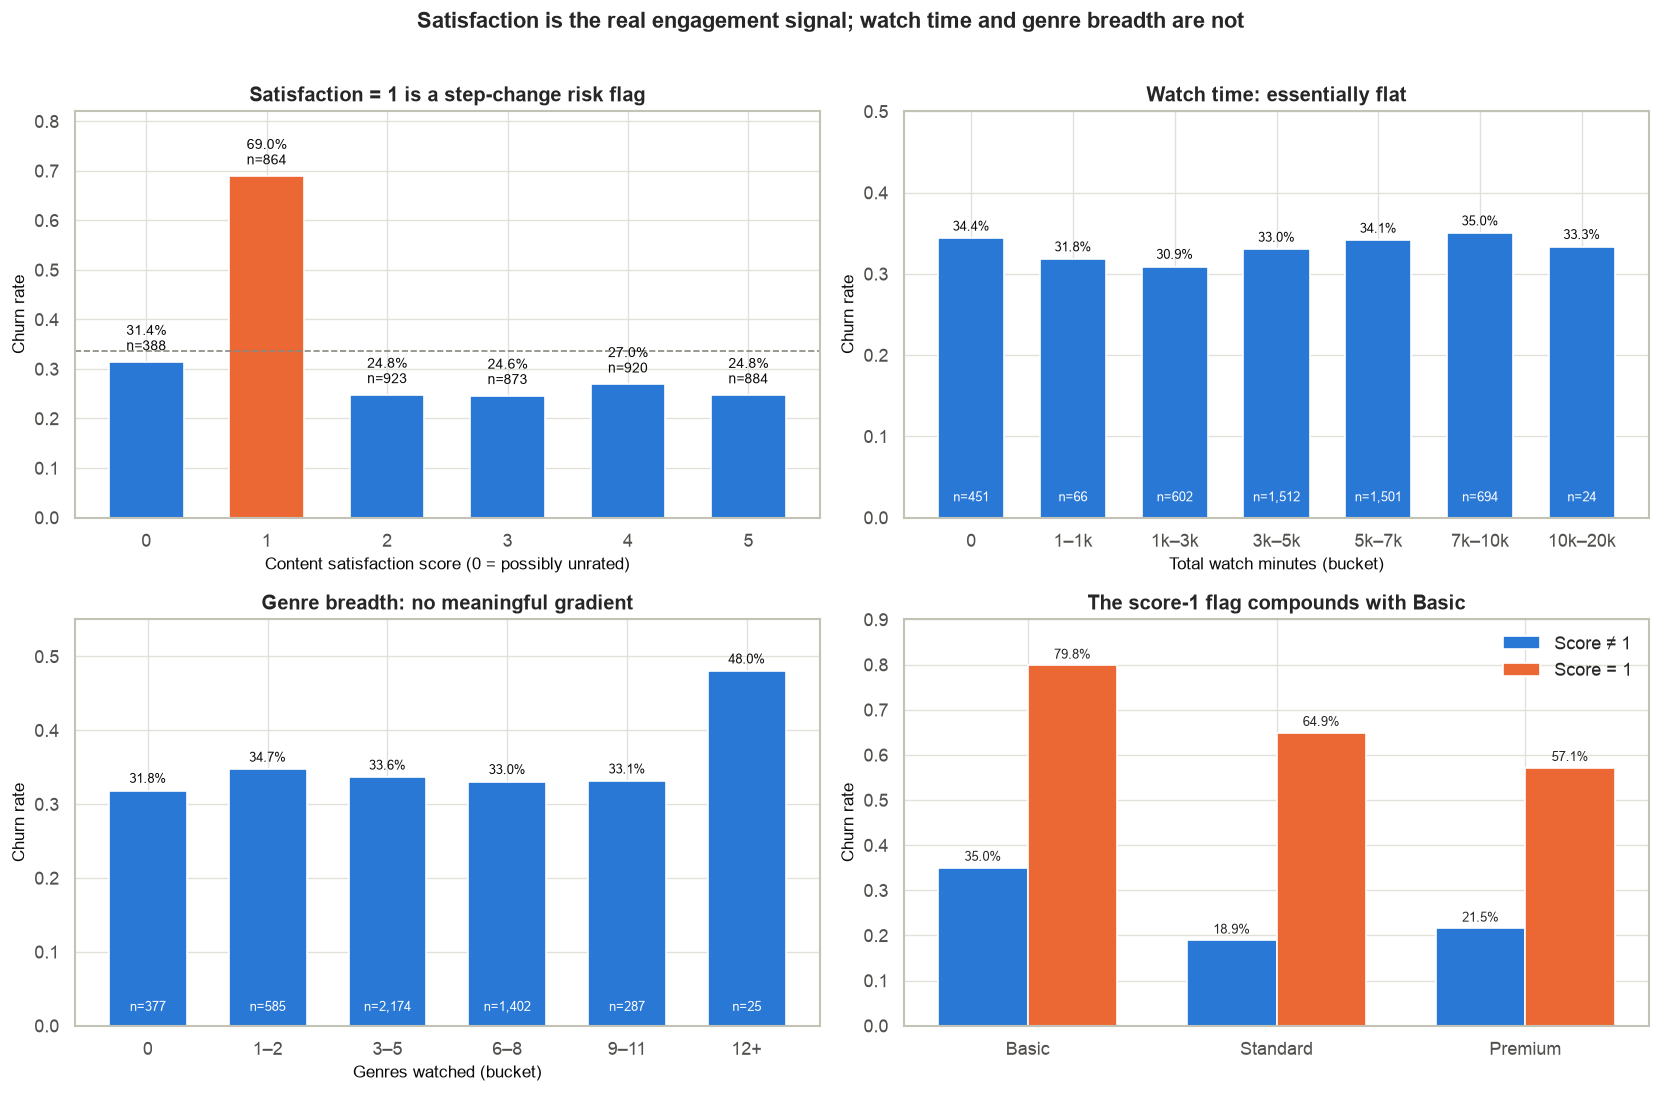

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Panel A: satisfaction curve
ax = axes[0, 0]
colors = [ORANGE if score == 1 else BLUE for score in q3_sat.index]
bars = ax.bar(q3_sat.index, q3_sat["churn_rate"], color=colors, width=0.62)
ax.set_ylim(0, 0.82)
ax.set_xticks(q3_sat.index)
ax.set_xlabel("Content satisfaction score (0 = possibly unrated)")
ax.set_ylabel("Churn rate")
ax.set_title("Satisfaction = 1 is a step-change risk flag")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.axhline(eda["churned"].mean(), color=GRAY, linestyle="--", linewidth=1)
for bar, (score, row) in zip(bars, q3_sat.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{row['churn_rate']:.1%}\nn={int(row['n']):,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color=INK,
    )

# Panel B: watch buckets
ax = axes[0, 1]
bars = ax.bar(q3_watch.index.astype(str), q3_watch["churn"], color=BLUE, width=0.65)
ax.set_ylim(0, 0.5)
ax.set_xlabel("Total watch minutes (bucket)")
ax.set_ylabel("Churn rate")
ax.set_title("Watch time: essentially flat")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
annotate_bars(ax, bars, [f"{r:.1%}" for r in q3_watch["churn"]], fontsize=8)
for bar, n in zip(bars, q3_watch["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 0.02, f"n={int(n):,}", ha="center", fontsize=7.5, color="white")

# Panel C: genre buckets
ax = axes[1, 0]
bars = ax.bar(q3_genre.index.astype(str), q3_genre["churn"], color=BLUE, width=0.65)
ax.set_ylim(0, 0.55)
ax.set_xlabel("Genres watched (bucket)")
ax.set_ylabel("Churn rate")
ax.set_title("Genre breadth: no meaningful gradient")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
annotate_bars(ax, bars, [f"{r:.1%}" for r in q3_genre["churn"]], fontsize=8)
for bar, n in zip(bars, q3_genre["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 0.02, f"n={int(n):,}", ha="center", fontsize=7.5, color="white")

# Panel D: satisfaction = 1 by plan
ax = axes[1, 1]
sat_plan = (
    eda[eda["content_satisfaction_score"].eq(1)]
    .groupby("plan_type", observed=True)["churned"]
    .agg(n="size", churn="mean")
    .reindex(PLAN_ORDER)
)
rest_plan = (
    eda[eda["content_satisfaction_score"].ne(1) & eda["content_satisfaction_score"].notna()]
    .groupby("plan_type", observed=True)["churned"]
    .agg(n="size", churn="mean")
    .reindex(PLAN_ORDER)
)
x = np.arange(len(PLAN_ORDER))
width = 0.36
ax.bar(x - width / 2, rest_plan["churn"], width=width, color=BLUE, label="Score ≠ 1")
ax.bar(x + width / 2, sat_plan["churn"], width=width, color=ORANGE, label="Score = 1")
ax.set_xticks(x)
ax.set_xticklabels(PLAN_ORDER)
ax.set_xlabel("")
ax.set_ylabel("Churn rate")
ax.set_title("The score-1 flag compounds with Basic")
ax.set_ylim(0, 0.9)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
for xi, plan in zip(x, PLAN_ORDER):
    ax.text(xi - width / 2, rest_plan.loc[plan, "churn"] + 0.015, f"{rest_plan.loc[plan, 'churn']:.1%}", ha="center", fontsize=8)
    ax.text(xi + width / 2, sat_plan.loc[plan, "churn"] + 0.015, f"{sat_plan.loc[plan, 'churn']:.1%}", ha="center", fontsize=8)

fig.suptitle("Satisfaction is the real engagement signal; watch time and genre breadth are not", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Executive takeaway:** *Satisfaction score 1 is the dominant behavioral red flag —
69.0% churn versus 25.9% for every other score (risk ratio 2.66, p < 0.001), rising
to 79.8% among Basic subscribers — whereas watch time and genre breadth show no
meaningful churn gradient.*

Two interpretation notes matter. First, score `0` behaves more like a “not rated”
bucket than an extreme low score (31.4% churn, much closer to the 2–5 range than to
score 1); the operational early-warning rule should target score `1`, not “low
scores” in general. Second, a
correlation would have hidden this entirely: the Spearman coefficient for
satisfaction is only −0.206 because the relationship is a spike at one value, not a
monotone slope. The business implication is to route score-1 subscribers, especially
on Basic, into a retention workflow; watch-time thresholds would add noise, not
signal. The 12+ genre bucket (n = 25) is too small to interpret and does not
overturn the flat pattern.

## Question 4 — Churn timing and lifecycle duration

**Business question:** What is the average active subscription duration from
registration to last activity for churned vs retained users? Does a shorter active
period precede churn?

**Method:** compute `tenure_days` from complete, plausible date pairs; compare
distributions with a Mann–Whitney U test and a bootstrap confidence interval for the
median difference. This analysis is constrained by the 81% date missingness and by
censoring: for retained users, `last_active_date` is a snapshot, not the true end of
the subscription.

In [30]:
q4 = eda[eda["tenure_days"].notna()].copy()
q4_stats = q4.groupby("churned")["tenure_days"].agg(["size", "mean", "median", "std", "min", "max"])
q4_stats.index = ["Stayed", "Churned"]
mwu_tenure = stats.mannwhitneyu(
    q4.loc[q4["churned"].eq(1), "tenure_days"],
    q4.loc[q4["churned"].eq(0), "tenure_days"],
)

# Bootstrap the median difference (churned minus stayed).
rng = np.random.default_rng(RANDOM_STATE)
churned_values = q4.loc[q4["churned"].eq(1), "tenure_days"].to_numpy()
stayed_values = q4.loc[q4["churned"].eq(0), "tenure_days"].to_numpy()
bootstrap_diffs = []
for _ in range(2_000):
    b_churned = rng.choice(churned_values, size=len(churned_values), replace=True)
    b_stayed = rng.choice(stayed_values, size=len(stayed_values), replace=True)
    bootstrap_diffs.append(np.median(b_churned) - np.median(b_stayed))
boot_low, boot_high = np.percentile(bootstrap_diffs, [2.5, 97.5])

display(q4_stats.style.format({"mean": "{:.1f}", "median": "{:.1f}", "std": "{:.1f}"}))
print(
    f"Usable tenure pairs: {len(q4):,} of {len(eda):,} analysis rows ({len(q4) / len(eda):.2%})\n"
    f"Mann–Whitney U: U = {mwu_tenure.statistic:.0f}, p = {mwu_tenure.pvalue:.3f}\n"
    f"Median difference (churned − stayed): {q4_stats.loc['Churned', 'median'] - q4_stats.loc['Stayed', 'median']:.0f} days; "
    f"bootstrap 95% CI [{boot_low:.0f}, {boot_high:.0f}]"
)

,size,mean,median,std,min,max
Stayed,129,375.3,290.0,334.7,4.000000,1253.000000
Churned,54,296.1,235.0,272.1,1.000000,1121.000000


Usable tenure pairs: 183 of 4,913 analysis rows (3.72%)
Mann–Whitney U: U = 3079, p = 0.217
Median difference (churned − stayed): -55 days; bootstrap 95% CI [-216, 78]


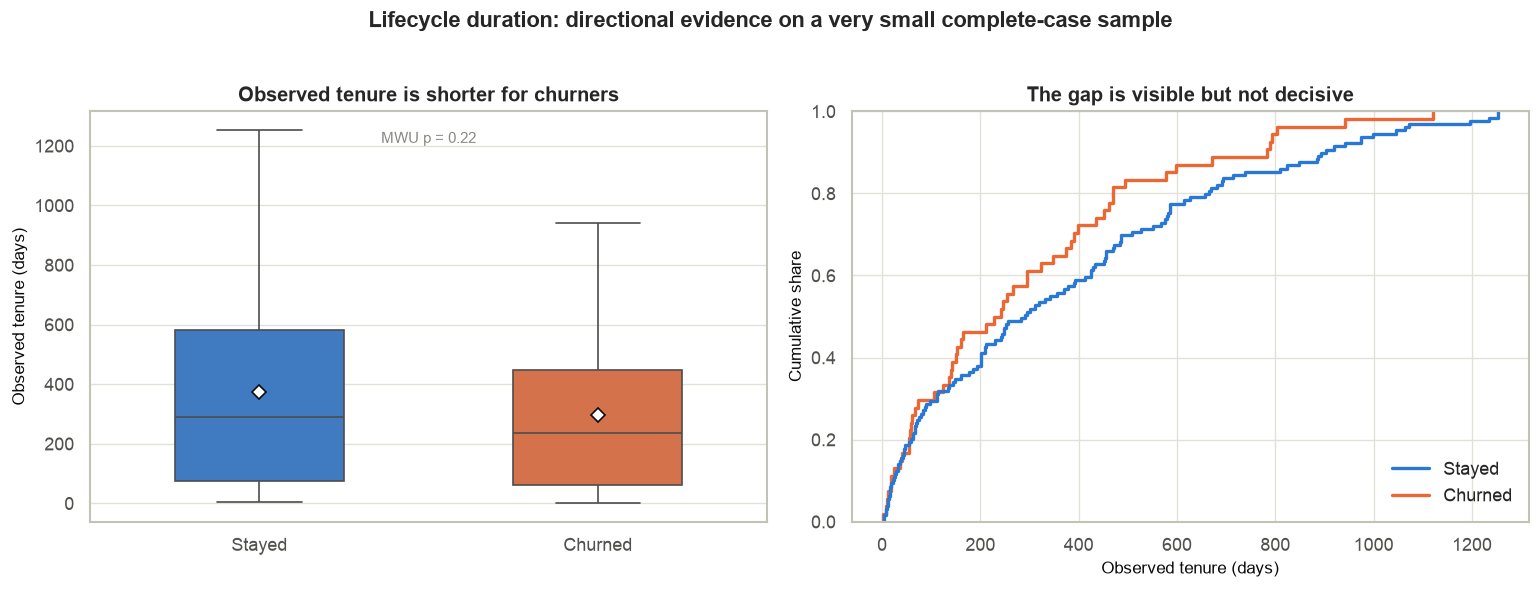

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
sns.boxplot(
    data=q4,
    x="churned",
    y="tenure_days",
    hue="churned",
    palette=[BLUE, ORANGE],
    width=0.5,
    showfliers=False,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 6},
    ax=ax,
    legend=False,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed", "Churned"])
ax.set_xlabel("")
ax.set_ylabel("Observed tenure (days)")
ax.set_title("Observed tenure is shorter for churners")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.text(
    0.5,
    0.95,
    f"MWU p = {mwu_tenure.pvalue:.2f}",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    color=GRAY,
)

ax = axes[1]
sns.ecdfplot(
    data=q4,
    x="tenure_days",
    hue="churned",
    palette=[BLUE, ORANGE],
    linewidth=2,
    legend=False,
    ax=ax,
)
ax.set_xlabel("Observed tenure (days)")
ax.set_ylabel("Cumulative share")
ax.set_title("The gap is visible but not decisive")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
handles = [
    Line2D([0], [0], color=BLUE, lw=2),
    Line2D([0], [0], color=ORANGE, lw=2),
]
ax.legend(handles, ["Stayed", "Churned"], frameon=False, loc="lower right")

fig.suptitle("Lifecycle duration: directional evidence on a very small complete-case sample", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Executive takeaway:** *Churned users’ observed active tenure is shorter at the
median (235 vs 290 days) and at the mean (296 vs 375 days), but the difference is not
statistically significant (Mann–Whitney p = 0.22) and rests on only 183 usable rows
(3.7% of the analysis population), so it is directional evidence rather than a
reliable lifecycle benchmark.*

The bootstrap interval for the median difference includes zero. Two structural
caveats limit the conclusion: 81% of date values are missing, and for retained users
`last_active_date` is a censored snapshot rather than a subscription end date. A
proper survival analysis would need a consistent observation cut-off and complete
registration dates. For now, the safe business statement is that early-life tenure
is worth monitoring, not that a specific “early churn window” has been established.

## Question 5 — Device-specific engagement and satisfaction

**Business question:** How do watch time and satisfaction vary by device type, and
does any device stand out?

**Method:** compare group medians and distributions with Kruskal–Wallis tests,
compare churn proportions with a chi-square test, and show the full distributions
rather than only means.

In [32]:
device_order = (
    eda.groupby("device_type", observed=True)["churned"]
    .size()
    .sort_values(ascending=False)
    .index.tolist()
)
q5 = (
    eda.groupby("device_type", observed=True)
    .agg(
        n=("churned", "size"),
        churned_count=("churned", "sum"),
        churn=("churned", "mean"),
        watch_mean=("total_watch_minutes", "mean"),
        watch_median=("total_watch_minutes", "median"),
        sat_mean=("content_satisfaction_score", "mean"),
        sat_median=("content_satisfaction_score", "median"),
    )
    .reindex(device_order)
)
q5[["churn_ci_low", "churn_ci_high"]] = [
    wilson_ci(int(successes), int(n)) for successes, n in zip(q5["churned_count"], q5["n"])
]

kruskal_watch = stats.kruskal(
    *[g["total_watch_minutes"].dropna() for _, g in eda.groupby("device_type", observed=True)]
)
kruskal_sat = stats.kruskal(
    *[g["content_satisfaction_score"].dropna() for _, g in eda.groupby("device_type", observed=True)]
)
device_chi2, device_p, device_dof, _ = stats.chi2_contingency(
    pd.crosstab(eda["device_type"], eda["churned"])
)

display(
    q5.style.format(
        {
            "churn": "{:.1%}",
            "watch_mean": "{:,.0f}",
            "watch_median": "{:,.0f}",
            "sat_mean": "{:.2f}",
            "sat_median": "{:.1f}",
            "churn_ci_low": "{:.1%}",
            "churn_ci_high": "{:.1%}",
        }
    )
)
print(
    f"Kruskal–Wallis watch time: H = {kruskal_watch.statistic:.2f}, p = {kruskal_watch.pvalue:.3f}\n"
    f"Kruskal–Wallis satisfaction: H = {kruskal_sat.statistic:.2f}, p = {kruskal_sat.pvalue:.3f}\n"
    f"Churn chi-square: χ² = {device_chi2:.2f}, df = {device_dof}, p = {device_p:.3f}"
)
print(f"Analysis rows excluded from Q5 for missing device_type: {int(eda['device_type'].isna().sum()):,}")

,n,churned_count,churn,watch_mean,watch_median,sat_mean,sat_median,churn_ci_low,churn_ci_high
device_type,,,,,,,,,
Mobile,1799,608,33.8%,"4,599","4,761",2.72,3.0,31.6%,36.0%
Smart TV,1130,379,33.5%,"4,526","4,698",2.78,3.0,30.8%,36.3%
Desktop,873,279,32.0%,"4,681","4,903",2.80,3.0,29.0%,35.1%
Tablet,472,163,34.5%,"4,488","4,678",2.80,3.0,30.4%,38.9%
Gaming Console,240,86,35.8%,"4,790","4,995",2.81,3.0,30.0%,42.1%


Kruskal–Wallis watch time: H = 5.21, p = 0.266
Kruskal–Wallis satisfaction: H = 2.08, p = 0.721
Churn chi-square: χ² = 1.81, df = 4, p = 0.771
Analysis rows excluded from Q5 for missing device_type: 399


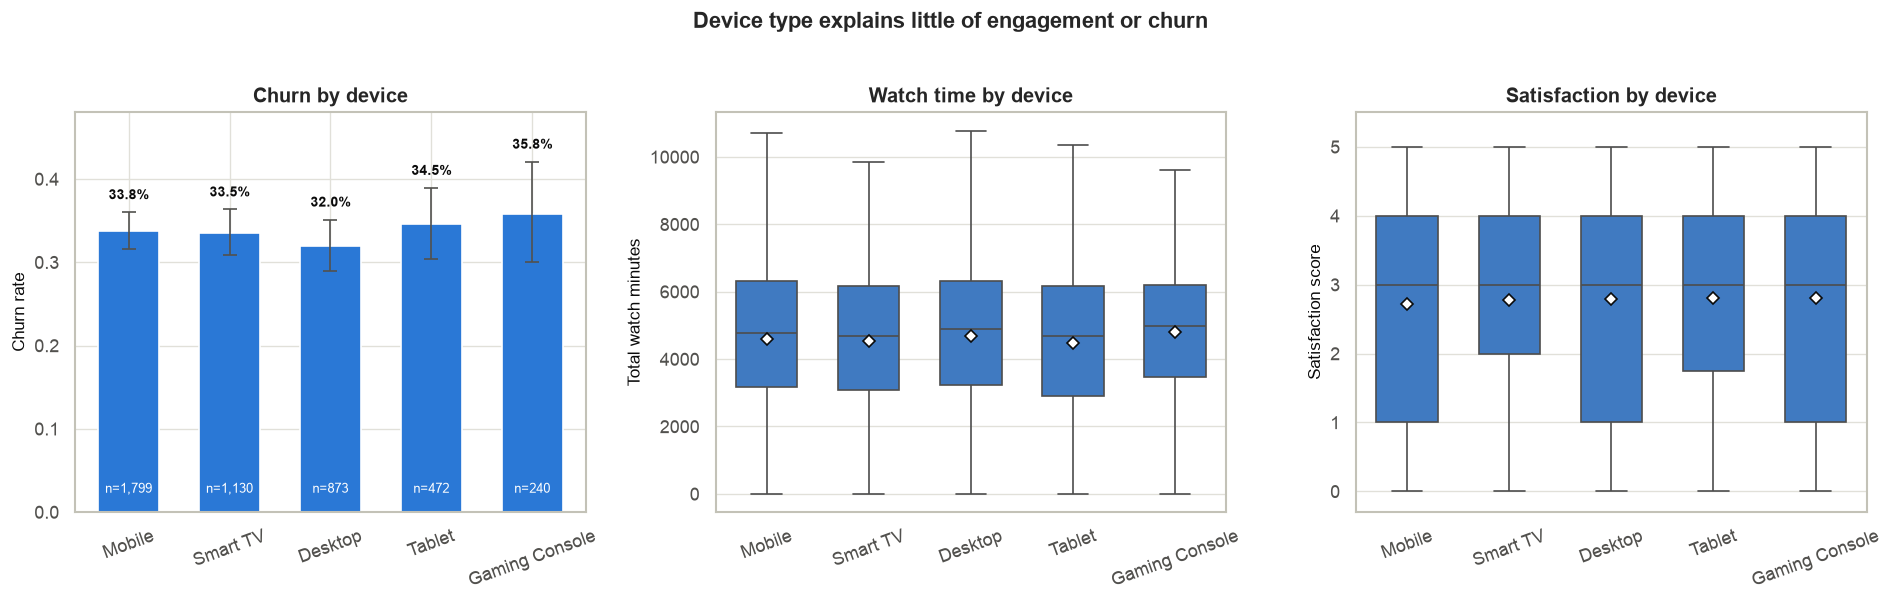

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))

ax = axes[0]
yerr = np.vstack(
    [q5["churn"] - q5["churn_ci_low"], q5["churn_ci_high"] - q5["churn"]]
)
bars = ax.bar(q5.index, q5["churn"], color=BLUE, width=0.6, yerr=yerr, capsize=4, error_kw={"ecolor": "#52514e", "lw": 1})
ax.set_ylim(0, 0.48)
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
ax.set_title("Churn by device")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=20)
for bar, rate, n, upper in zip(bars, q5["churn"], q5["n"], q5["churn_ci_high"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        upper + 0.012,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        0.02,
        f"n={int(n):,}",
        ha="center",
        va="bottom",
        fontsize=7.5,
        color="white",
    )

ax = axes[1]
sns.boxplot(
    data=eda,
    x="device_type",
    y="total_watch_minutes",
    order=device_order,
    color=BLUE,
    width=0.6,
    showfliers=False,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 5},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Total watch minutes")
ax.set_title("Watch time by device")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=20)

ax = axes[2]
sns.boxplot(
    data=eda,
    x="device_type",
    y="content_satisfaction_score",
    order=device_order,
    color=BLUE,
    width=0.6,
    showfliers=False,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 5},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Satisfaction score")
ax.set_title("Satisfaction by device")
ax.set_ylim(-0.3, 5.5)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=20)

fig.suptitle("Device type explains little of engagement or churn", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Executive takeaway:** *Device type is not a meaningful engagement or churn
differentiator here — median watch time ranges only 4,678–4,995 minutes, mean
satisfaction ranges 2.72–2.81, and both Kruskal–Wallis tests are non-significant
(p = 0.27 and p = 0.72) — so device-specific UX investment is not supported by this
dataset.*

This is a useful null result. The sample is large enough to detect a meaningful
difference, and the distributions overlap almost completely. The practical
implication is to prioritise product improvements by plan and satisfaction cohort,
not by device surface. Device may still matter for feature adoption or streaming
quality; this dataset does not contain those measures. The 399 analysis rows with a
missing device type (8.1%) are excluded from the device comparison.

### Part 5 synthesis

| Question | Signal | Business action |
|---|---|---|
| Q1 — Plan | **Strong:** Basic 42.9% vs ~27–28% for Standard/Premium | Focus retention economics and value communication on Basic |
| Q2 — Promo | **Null:** 33.3% vs 33.6% churn; price lift ≈ 0 | Stop treating binary promo usage as a retention lever; measure discount depth |
| Q3 — Engagement | **Strong but non-linear:** score 1 = 69.0% churn; watch/genres flat | Build an early-warning trigger on satisfaction score = 1, especially on Basic |
| Q4 — Tenure | **Weak / underpowered:** shorter tenure for churners, p = 0.22, n = 183 | Monitor early tenure, but do not set a hard early-churn benchmark yet |
| Q5 — Device | **Null:** all tests non-significant | Do not prioritise device-specific UX from this evidence |

---
# Part 6 — Advanced Data Preparation for Machine Learning

### Target and leakage principles

The target is **`churned`** (binary). The modelling pipeline follows four rules:

1. **Split before fitting anything.** The 80/20 stratified split happens before any
   imputer, encoder or scaler sees the data.
2. **Never impute the target.** Records with a missing/corrupted `churned` value are
   excluded from the supervised table.
3. **No identity or outcome-timing leakage.** IDs are dropped. `last_active_date` and
   `tenure_days` are dropped because churn is essentially defined by inactivity; a
   model that sees them would be predicting the label from its own definition.
4. **Train-only statistics.** All medians, modes, category vocabularies and scaling
   parameters are learned on `X_train` and applied unchanged to `X_test`.

In [34]:
model = merged[merged["churned"].notna()].copy()
model["churned"] = model["churned"].astype("int64")

SNAPSHOT_DATE = model["last_active_date"].max()
print(f"Observation snapshot date (max last_active_date): {SNAPSHOT_DATE.date()}")
print(f"Modelling rows: {len(model):,}; churn rate: {model['churned'].mean():.2%}")

# Temporal feature: account age at the snapshot. This uses registration date only,
# so it does not leak the churn/inactivity outcome.
model["account_age_days"] = (SNAPSHOT_DATE - model["registration_date"]).dt.days
model["registration_year"] = model["registration_date"].dt.year

# Domain-informed non-linear features.
model["has_kids_category"] = (
    model["has_kids_profile"].map({1: "Yes", 0: "No"}).fillna("Unknown")
)
model["sat_is_1"] = (model["content_satisfaction_score"] == 1).astype("int64")
model["zero_watch"] = (model["total_watch_minutes"] == 0).astype("int64")
model["zero_genres"] = (model["num_genres_watched"] == 0).astype("int64")

feature_plan = pd.DataFrame(
    [
        {"feature_group": "plan_type", "treatment": "One-hot; missing → 'Unknown'", "why": "Core commercial tier"},
        {"feature_group": "country", "treatment": "One-hot; missing → 'Unknown'", "why": "Market mix"},
        {"feature_group": "device_type", "treatment": "One-hot; missing → 'Unknown'", "why": "Surface mix"},
        {"feature_group": "has_kids_category", "treatment": "One-hot; missing → 'Unknown'", "why": "Household composition"},
        {"feature_group": "promo_used", "treatment": "Binary passthrough", "why": "Promo exposure"},
        {"feature_group": "total_watch_minutes, num_genres_watched, content_satisfaction_score", "treatment": "Median impute + missing indicator + robust scale", "why": "Engagement signals"},
        {"feature_group": "account_age_days, registration_year", "treatment": "Median impute + missing indicator + robust scale", "why": "Temporal signals from registration date"},
        {"feature_group": "sat_is_1, zero_watch, zero_genres", "treatment": "Binary passthrough", "why": "Non-linear and zero-inflation structure discovered in EDA"},
    ]
)
display(feature_plan)

exclusions = pd.DataFrame(
    [
        {"column": "user_id / subscription_id", "reason": "Identifiers; no predictive meaning and would make the split leak row identity."},
        {"column": "last_active_date / tenure_days", "reason": "Churn is defined by inactivity; including these would leak the outcome definition."},
        {"column": "registration_date (raw)", "reason": "81% missing; represented by account_age_days and registration_year with missing indicators."},
        {"column": "monthly_price", "reason": "75.7% missing; imputing three of four values would be mostly synthetic. Retained in the cleaned table for Q2."},
    ]
)
display(exclusions)

Observation snapshot date (max last_active_date): 2023-10-31
Modelling rows: 4,913; churn rate: 33.54%


,feature_group,treatment,why
0,plan_type,One-hot; missing → 'Unknown',Core commercial tier
1,country,One-hot; missing → 'Unknown',Market mix
2,device_type,One-hot; missing → 'Unknown',Surface mix
3,has_kids_category,One-hot; missing → 'Unknown',Household composition
4,promo_used,Binary passthrough,Promo exposure
5,"total_watch_minutes, num_genres_watched, conte...",Median impute + missing indicator + robust scale,Engagement signals
6,"account_age_days, registration_year",Median impute + missing indicator + robust scale,Temporal signals from registration date
7,"sat_is_1, zero_watch, zero_genres",Binary passthrough,Non-linear and zero-inflation structure discov...


,column,reason
0,user_id / subscription_id,Identifiers; no predictive meaning and would m...
1,last_active_date / tenure_days,Churn is defined by inactivity; including thes...
2,registration_date (raw),81% missing; represented by account_age_days a...
3,monthly_price,75.7% missing; imputing three of four values w...


In [35]:
NUM_CONT = [
    "total_watch_minutes",
    "num_genres_watched",
    "content_satisfaction_score",
    "account_age_days",
    "registration_year",
]
NUM_BIN = ["promo_used", "sat_is_1", "zero_watch", "zero_genres"]
CAT_COLS = ["plan_type", "country", "device_type", "has_kids_category"]

# Explicit dtypes prevent pandas nullable types from producing an object matrix.
for col in NUM_CONT:
    model[col] = pd.to_numeric(model[col], errors="coerce").astype("float64")
for col in NUM_BIN:
    model[col] = model[col].astype("int64")
for col in CAT_COLS:
    model[col] = model[col].astype("object")
    model[col] = model[col].where(model[col].notna(), np.nan)

X = model[NUM_CONT + NUM_BIN + CAT_COLS]
y = model["churned"]

print("Feature dtypes:")
print(X.dtypes.to_string())
print(f"\nX shape: {X.shape}; y shape: {y.shape}")

Feature dtypes:
total_watch_minutes           float64
num_genres_watched            float64
content_satisfaction_score    float64
account_age_days              float64
registration_year             float64
promo_used                      int64
sat_is_1                        int64
zero_watch                      int64
zero_genres                     int64
plan_type                      object
country                        object
device_type                    object
has_kids_category              object

X shape: (4913, 13); y shape: (4913,)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    [
        {"split": "Train", "rows": len(X_train), "churn_rate": y_train.mean()},
        {"split": "Test", "rows": len(X_test), "churn_rate": y_test.mean()},
    ]
)
display(split_summary.style.format({"churn_rate": "{:.2%}"}))

print("Remaining missing values on X_train (before imputation):")
train_missing = (
    X_train.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_pct=lambda d: d["missing_count"] / len(X_train))
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(train_missing.style.format({"missing_pct": "{:.1%}"}))

,split,rows,churn_rate
0,Train,3930,33.54%
1,Test,983,33.57%


Remaining missing values on X_train (before imputation):


,missing_count,missing_pct
account_age_days,3171,80.7%
registration_year,3171,80.7%
device_type,328,8.3%
country,325,8.3%
plan_type,314,8.0%
total_watch_minutes,51,1.3%
num_genres_watched,46,1.2%
content_satisfaction_score,44,1.1%


In [37]:
numeric_pipeline = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", RobustScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipeline, NUM_CONT),
        ("bin", "passthrough", NUM_BIN),
        ("cat", categorical_pipeline, CAT_COLS),
    ],
    remainder="drop",
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Prepared train matrix: {X_train_prepared.shape}")
print(f"Prepared test matrix:  {X_test_prepared.shape}")
print(f"Matrix dtype: {X_train_prepared.dtype}")
print(f"NaNs in prepared train/test: {np.isnan(X_train_prepared).sum()} / {np.isnan(X_test_prepared).sum()}")
print(f"Number of model-ready features (excluding target): {len(feature_names)}")
print("\nFeature names:")
for name in feature_names:
    print(f"  - {name}")

Prepared train matrix: (3930, 36)
Prepared test matrix:  (983, 36)
Matrix dtype: float64
NaNs in prepared train/test: 0 / 0
Number of model-ready features (excluding target): 36

Feature names:
  - num__total_watch_minutes
  - num__num_genres_watched
  - num__content_satisfaction_score
  - num__account_age_days
  - num__registration_year
  - num__missingindicator_total_watch_minutes
  - num__missingindicator_num_genres_watched
  - num__missingindicator_content_satisfaction_score
  - num__missingindicator_account_age_days
  - num__missingindicator_registration_year
  - bin__promo_used
  - bin__sat_is_1
  - bin__zero_watch
  - bin__zero_genres
  - cat__plan_type_Basic
  - cat__plan_type_Premium
  - cat__plan_type_Standard
  - cat__plan_type_Unknown
  - cat__country_Australia
  - cat__country_Brazil
  - cat__country_Canada
  - cat__country_France
  - cat__country_Germany
  - cat__country_Japan
  - cat__country_UK
  - cat__country_USA
  - cat__country_Unknown
  - cat__device_type_Desktop
 

In [38]:
train_prepared = pd.DataFrame(X_train_prepared, columns=feature_names)
train_prepared["churned"] = y_train.reset_index(drop=True)

test_prepared = pd.DataFrame(X_test_prepared, columns=feature_names)
test_prepared["churned"] = y_test.reset_index(drop=True)

train_prepared.to_csv("train_prepared.csv", index=False)
test_prepared.to_csv("test_prepared.csv", index=False)

print(f"train_prepared.csv → {train_prepared.shape[0]:,} rows × {train_prepared.shape[1]} columns")
print(f"test_prepared.csv  → {test_prepared.shape[0]:,} rows × {test_prepared.shape[1]} columns")
display(train_prepared.head(3))

train_prepared.csv → 3,930 rows × 37 columns
test_prepared.csv  → 983 rows × 37 columns


,num__total_watch_minutes,num__num_genres_watched,num__content_satisfaction_score,num__account_age_days,num__registration_year,num__missingindicator_total_watch_minutes,num__missingindicator_num_genres_watched,num__missingindicator_content_satisfaction_score,num__missingindicator_account_age_days,num__missingindicator_registration_year,bin__promo_used,bin__sat_is_1,bin__zero_watch,bin__zero_genres,cat__plan_type_Basic,cat__plan_type_Premium,cat__plan_type_Standard,cat__plan_type_Unknown,cat__country_Australia,cat__country_Brazil,cat__country_Canada,cat__country_France,cat__country_Germany,cat__country_Japan,cat__country_UK,cat__country_USA,cat__country_Unknown,cat__device_type_Desktop,cat__device_type_Gaming Console,cat__device_type_Mobile,cat__device_type_Smart TV,cat__device_type_Tablet,cat__device_type_Unknown,cat__has_kids_category_No,cat__has_kids_category_Unknown,cat__has_kids_category_Yes,churned
0,0.290982,0.000000,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1
1,-0.343465,1.000000,-1.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1
2,0.781930,0.666667,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0


In [39]:
train_check = pd.read_csv("train_prepared.csv")
test_check = pd.read_csv("test_prepared.csv")

checks = pd.DataFrame(
    [
        {"check": "Train file exists", "value": Path("train_prepared.csv").exists()},
        {"check": "Test file exists", "value": Path("test_prepared.csv").exists()},
        {"check": "Train shape", "value": str(train_check.shape)},
        {"check": "Test shape", "value": str(test_check.shape)},
        {"check": "Train columns == Test columns", "value": list(train_check.columns) == list(test_check.columns)},
        {"check": "NaNs in train", "value": int(train_check.isna().sum().sum())},
        {"check": "NaNs in test", "value": int(test_check.isna().sum().sum())},
        {"check": "Train churn rate", "value": f"{train_check['churned'].mean():.2%}"},
        {"check": "Test churn rate", "value": f"{test_check['churned'].mean():.2%}"},
        {"check": "Target values are 0/1", "value": bool(train_check["churned"].isin([0, 1]).all() and test_check["churned"].isin([0, 1]).all())},
    ]
)
display(checks)

,check,value
0,Train file exists,True
1,Test file exists,True
2,Train shape,"(3930, 37)"
3,Test shape,"(983, 37)"
4,Train columns == Test columns,True
5,NaNs in train,0
6,NaNs in test,0
7,Train churn rate,33.54%
8,Test churn rate,33.57%
9,Target values are 0/1,True


In [40]:
leakage_checks = pd.DataFrame(
    [
        {"control": "Deduplicated before the split", "status": "PASS", "evidence": f"{len(df) - len(merged):,} duplicate rows merged before modeling"},
        {"control": "Stratified 80/20 split", "status": "PASS", "evidence": f"Train {len(X_train):,} / Test {len(X_test):,}; churn {y_train.mean():.2%} vs {y_test.mean():.2%}"},
        {"control": "Identifiers excluded", "status": "PASS", "evidence": "user_id and subscription_id are not in the feature lists"},
        {"control": "Outcome-timing features excluded", "status": "PASS", "evidence": "last_active_date and tenure_days are not in X"},
        {"control": "Imputers fitted on X_train only", "status": "PASS", "evidence": "preprocessor.fit_transform(X_train); transform(X_test)"},
        {"control": "Encoders fitted on X_train only", "status": "PASS", "evidence": "OneHotEncoder is inside the fitted ColumnTransformer"},
        {"control": "Scaler fitted on X_train only", "status": "PASS", "evidence": "RobustScaler is inside the fitted ColumnTransformer"},
        {"control": "Target never imputed", "status": "PASS", "evidence": f"{int(merged['churned'].isna().sum())} target-missing records excluded; no target transformer"},
            ]
)
display(leakage_checks)

,control,status,evidence
0,Deduplicated before the split,PASS,223 duplicate rows merged before modeling
1,Stratified 80/20 split,PASS,"Train 3,930 / Test 983; churn 33.54% vs 33.57%"
2,Identifiers excluded,PASS,user_id and subscription_id are not in the fea...
3,Outcome-timing features excluded,PASS,last_active_date and tenure_days are not in X
4,Imputers fitted on X_train only,PASS,preprocessor.fit_transform(X_train); transform...
5,Encoders fitted on X_train only,PASS,OneHotEncoder is inside the fitted ColumnTrans...
6,Scaler fitted on X_train only,PASS,RobustScaler is inside the fitted ColumnTransf...
7,Target never imputed,PASS,64 target-missing records excluded; no target ...


### Part 6 verdict

The prepared matrices are **leakage-free by construction**:

- The split occurs before the first transformer.
- The target is never imputed.
- Identity and inactivity-timing fields are excluded.
- All imputation, one-hot vocabularies and scaling statistics are learned on
  `X_train` and applied to `X_test`.
- The two exported files have identical feature columns, no missing values, and a
  preserved 33.5% churn rate in both splits.

The one deliberate omission is `monthly_price`: with 75.7% missing, an imputed price
column would be mostly synthetic. It remains available in `dataset_cleaned.csv` for
the business analysis. If a downstream model needs it, the correct approach is a
separate sensitivity experiment with an explicit missingness indicator, not silent
median imputation.

---
# Conclusion

## What the data supports

1. **Plan tier is the clearest commercial lever.** Basic churn is 42.9%, about 16
   percentage points above the other tiers. Because Basic is the largest tier, it
   drives a disproportionate share of total churn.
2. **Satisfaction score 1 is the strongest actionable behavioral flag.** It is a
   step-change, not a gradient: 69.0% churn versus 25.9% for all other scores. The
   effect compounds with Basic (79.8% churn). A score-1 early-warning workflow is a
   better use of retention budget than watch-time thresholds.
3. **Watch time, genre breadth, device type and promo usage are null signals** in
   this dataset. Reporting them as null findings is more useful than forcing a
   narrative.
4. **Tenure direction is consistent but underpowered.** Churners have shorter
   observed tenure, but 81% date missingness and censoring make the estimate fragile.

## What the data does not support

- **Causal claims.** The analysis is observational; plan assignment, satisfaction,
  and promo use are not randomised.
- **A precise early-churn window.** Only 183 records have usable tenure, and retained
  users are right-censored.
- **A definitive promo ROI statement.** The binary promo field lacks discount depth
  and acquisition-channel context; blanks are treated as “no promo”.
- **A device-specific UX priority.** The device tests are null.

## Data-quality lessons

- Identity fields cannot be trusted without normalization; 282 rows had no usable ID
  before recovery, and 36 valid-looking IDs disagreed across the two ID fields.
- Duplicates are not always exact copies. Coalescing recovered prices, dates and even
  seven corrupted targets.
- Extreme values can be sentinels, not users. Exact repetition and domain
  impossibility are stronger evidence than an IQR fence.
- Missingness has multiple mechanisms. Treating all blanks as “missing” would have
  destroyed the meaning of the promo field and contaminated the ML matrix with
  mostly synthetic imputed prices.

## Deliverables

| Artifact | Contents |
|---|---|
| `TP1_Group_5.ipynb` | This executed notebook |
| `dataset_cleaned.csv` | 4,977 deduplicated, coerced, sentinel-triaged records |
| `train_prepared.csv` | 3,930 leakage-free prepared training rows (36 features + target) |
| `test_prepared.csv` | 983 leakage-free prepared test rows (36 features + target) |

**Reproducibility:** run top-to-bottom from the repository root with Python 3.12 and
the pinned environment (`uv sync`, or `pip install -r requirements.txt`). All random
operations use `RANDOM_STATE = 42`.